In [8]:
import os
from osgeo import gdal
import os
from sklearn.metrics import accuracy_score, f1_score, jaccard_score, precision_score, recall_score
import matplotlib.pyplot as plt
import SinkTools2 as st
import tqdm
import torch
from osgeo import gdal, ogr
import numpy as np
import torch.nn.functional as F
from model import build_unet
import time
import SinkTools2 as st
import argparse
import logging
from logging.handlers import TimedRotatingFileHandler
import sys
import subprocess


/Users/nirgut/PycharmProjects/Sinkholes_ml/UNet/SinkTools2.py:16: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  import geopandas as gpd


In [27]:
st.clip_raster_by_raster('/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_new_boundaries.tif', '/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/prob_sum_group19.tif.tif', '/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_test_groups/group19.tif')

In [13]:
import os
import subprocess
import tempfile

def combine_rasters_with_gdal(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Create a temporary file to hold the input file paths
    with tempfile.NamedTemporaryFile(delete=False, mode='w', suffix='.txt') as temp_file:
        temp_file_name = temp_file.name
        temp_file.write("\n".join(input_files))

    # Build the gdal_merge command
    gdal_merge_command = [
        'gdal_merge.py',
        '-o', output_file,
        '-n', '0',  # NoData value to ignore
        '-a_nodata', '-32767',  # NoData value to set in the output
    ] + input_files  # Add the input .tif files directly to the command

    # Execute the command
    subprocess.run(gdal_merge_command)

    # Cleanup the temporary file
    os.remove(temp_file_name)

In [14]:
predict_folder = '/Users/nirgut/Documents/Master_Files/Raster_Files/2023_LiDAR'
output_file = '/Users/nirgut/Documents/Master_Files/Raster_Files/2023_LiDAR/2023_full_LiDAR.tif'
combine_rasters_with_gdal(predict_folder, output_file)

0...10...20...30...40...50...60...70...80...90...100 - done.


In [4]:
def raster_to_vector(input_raster_path, output_vector_path):
    # Open the input raster
    raster = gdal.Open(input_raster_path)
    if raster is None:
        print(f"Unable to open input raster {input_raster_path}")
        return

    # Get raster information
    xsize = raster.RasterXSize
    ysize = raster.RasterYSize
    geotransform = raster.GetGeoTransform()
    projection = raster.GetProjection()

    # Create a new vector layer
    driver = ogr.GetDriverByName('ESRI Shapefile')
    output_vector = driver.CreateDataSource(output_vector_path)
    layer = output_vector.CreateLayer('output', srs=None)

    # Add a single field to the layer
    layer.CreateField(ogr.FieldDefn('value', ogr.OFTInteger))

    # Rasterize the vector layer
    gdal.RasterizeLayer(raster, [1], layer, options=['ATTRIBUTE=value'])

    # Close the vector layer
    output_vector = None

In [5]:
    
    
    output_shp = '/Users/nirgut/Documents/Master_Files/pipeline_testing/merged_new.shp'
    # raster_to_vector(output_file, output_shp)

    # converting to polygons
    st.pred2polygons(output_file, output_shp)
    st.del_0val_polygons(output_shp)


NameError: name 'st' is not defined

In [19]:
import geopandas as gpd
import pandas as pd
from datetime import datetime

def filter_sinkholes_by_year(shapefile_path, year, output_path):
    # Load the shapefile
    gdf = gpd.read_file(shapefile_path)
    
    # Create the start and end year columns
    gdf['Start_Year'] = gdf['Start_Date']
    gdf['End_Year'] = gdf['End_Date']
    
    # Filter based on the given year
    filtered_gdf = gdf[
        (gdf['Start_Year'] <= year) &
        ((gdf['End_Year'] > year) | (gdf['End_Date'].isnull()))
    ]
    
    # Save the filtered GeoDataFrame as a new shapefile
    filtered_gdf.to_file(output_path, driver='ESRI Shapefile')

    return filtered_gdf

# Example usage
shapefile_path = '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2023_main.shp'
output_path = '/Users/nirgut/Documents/Master_Files/Sinkholes_2023_main_20240310/Sinkholes_2016_filtered.shp'
year = 2016

filtered_gdf = filter_sinkholes_by_year(shapefile_path, year, output_path)


In [6]:
def combine_rasters_with_gdal(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Create a temporary file to hold the input file paths
    with tempfile.NamedTemporaryFile(delete=False, mode='w', suffix='.txt') as temp_file:
        temp_file_name = temp_file.name
        temp_file.write("\n".join(input_files))

    # Build the gdal_merge command
    gdal_merge_command = [
        'gdal_merge.py',
        '-o', output_file,
        '-n', '0',  # NoData value to ignore
        '-a_nodata', '-32767',  # NoData value to set in the output
        '-pct',  # Use the maximum value in overlapping regions
        '--optfile', temp_file_name  # Provide the list of files via optfile
    ]

    # Execute the command
    subprocess.run(gdal_merge_command)

    # Cleanup the temporary file
    os.remove(temp_file_name)
    
tiles_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions'
output_file = '/Users/nirgut/Documents/Master_Files/pipeline_testing/mask_05_2020.tif'

combine_rasters_with_gdal(tiles_folder, output_file)

Traceback (most recent call last):
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/bin/gdal_merge.py", line 12, in <module>
    sys.exit(main(sys.argv))
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_merge.py", line 633, in main
    return gdal_merge(argv)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_merge.py", line 507, in gdal_merge
    file_infos = names_to_fileinfos(names)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_merge.py", line 213, in names_to_fileinfos
    if fi.init_from_name(name) == 1:
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_merge.py", line 247, in init_from_name
    fh = gdal.Open(filename)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo/gdal.py", line 4716, in Open
    return _gdal.Open(*args)
KeyboardInterrupt


KeyboardInterrupt: 

In [23]:
def raster_to_vector(input_raster_path, output_vector_path):
    # Open the input raster
    raster = gdal.Open(input_raster_path)
    if raster is None:
        print(f"Unable to open input raster {input_raster_path}")
        return

    # Get raster information
    xsize = raster.RasterXSize
    ysize = raster.RasterYSize
    geotransform = raster.GetGeoTransform()
    projection = raster.GetProjection()

    # Create a new vector layer
    driver = ogr.GetDriverByName('ESRI Shapefile')
    output_vector = driver.CreateDataSource(output_vector_path)
    layer = output_vector.CreateLayer('output', srs=None)

    # Add a single field to the layer
    layer.CreateField(ogr.FieldDefn('value', ogr.OFTInteger))

    # Rasterize the vector layer
    gdal.RasterizeLayer(raster, [1], layer, options=['ATTRIBUTE=value'])

    # Close the vector layer
    output_vector = None

# Binary Mosaic to Shapefile
output_shp = '/Users/nirgut/Documents/Master_Files/pipeline_testing/preds_05_2020.shp'
# raster_to_vector(output_file, output_shp)

# converting to polygons
st.pred2polygons(output_file, output_shp)
st.del_0val_polygons(output_shp)

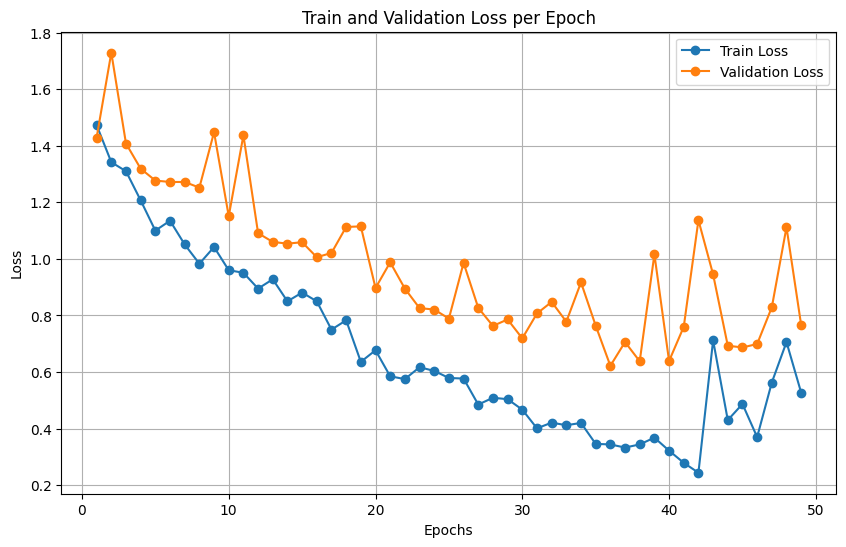

In [26]:
import matplotlib.pyplot as plt

# Extracted loss values
train_loss = [
    1.473, 1.342, 1.310, 1.207, 1.100, 1.135, 1.051, 0.983, 1.042, 0.960, 
    0.951, 0.895, 0.928, 0.850, 0.881, 0.850, 0.750, 0.783, 0.636, 0.677, 
    0.585, 0.575, 0.617, 0.604, 0.579, 0.577, 0.485, 0.509, 0.504, 0.467, 0.401, 0.421, 0.412, 0.420, 0.346, 0.344, 0.333, 0.344, 0.368, 0.322, 0.279, 0.244, 0.712, 0.430, 0.487, 0.370, 0.563, 0.706, 0.527
]

val_loss = [
    1.429, 1.729, 1.408, 1.319, 1.277, 1.272, 1.272, 1.252, 1.448, 1.151, 
    1.437, 1.091, 1.060, 1.054, 1.059, 1.006, 1.021, 1.113, 1.115, 0.897, 
    0.988, 0.895, 0.826, 0.821, 0.789, 0.986, 0.827, 0.763, 0.786, 0.719, 0.807, 0.848, 0.778, 0.917, 0.764, 0.622, 0.706, 0.638, 1.016, 0.639, 0.760, 1.137, 0.945, 0.693, 0.687, 0.699, 0.829, 1.112, 0.766
]

# Number of epochs (length of the lists)
epochs = list(range(1, len(train_loss) + 1))

# Plotting the loss
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, marker='o', label='Train Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train and Validation Loss per Epoch')
plt.legend()
plt.grid(True)
plt.show()


In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('/Users/nirgut/Documents/Master_Files/Plots/04.09.24 - unet model 50 overlap/UNet Preformance.csv')

print(df)






    threshold   sens   spec    acc  precision     f1  jaccard
0         0.0  0.112  1.000  0.112      1.000  0.202    0.112
1         0.1  0.715  0.960  0.936      0.729  0.722    0.565
2         0.2  0.751  0.960  0.939      0.686  0.717    0.559
3         0.3  0.769  0.957  0.939      0.662  0.711    0.550
4         0.4  0.781  0.955  0.939      0.643  0.705    0.545
5         0.5  0.792  0.953  0.939      0.626  0.699    0.538
6         0.6  0.805  0.951  0.939      0.607  0.692    0.529
7         0.7  0.821  0.948  0.938      0.581  0.681    0.516
8         0.8  0.847  0.943  0.937      0.536  0.657    0.489
9         0.9  0.886  0.934  0.931      0.446  0.594    0.422
10        1.0  0.991  0.891  0.892      0.041  0.078    0.041
0     0.0
1     0.1
2     0.2
3     0.3
4     0.4
5     0.5
6     0.6
7     0.7
8     0.8
9     0.9
10    1.0
Name: threshold, dtype: float64


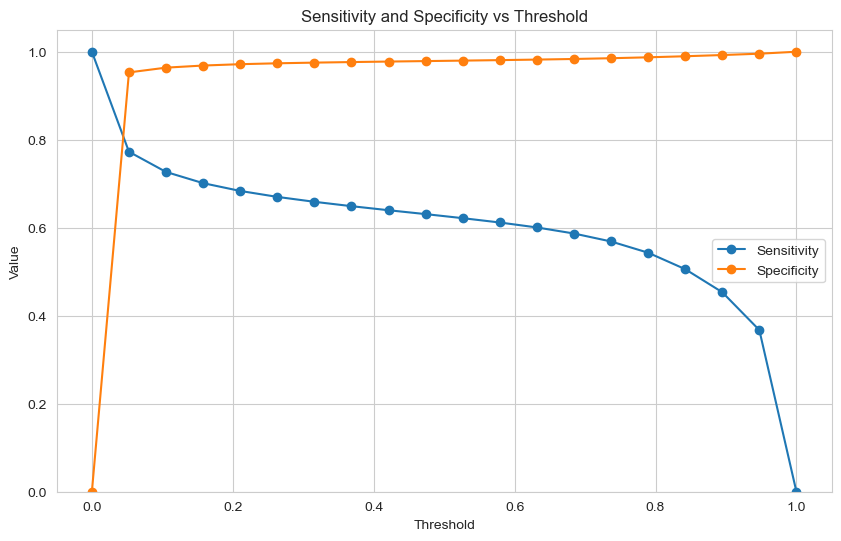

In [4]:
# sens = df['sens']
# print(sens)
# spec = df['spec']
# print(type(spec))
# threshold = df['threshold']

sens = [1. ,        0.77265361 ,0.72675501 ,0.70127825 ,0.68359661 ,0.67008543,
 0.65892002 ,0.64899801 ,0.63976327 ,0.63093922 ,0.62172124, 0.61187811,
 0.60061854, 0.58685739, 0.56874831, 0.54323211, 0.50584449, 0.45343065,
 0.36737959, 0.        ]

spec = [0.,         0.95299874, 0.96380305, 0.96860157, 0.9716502,  0.97370127,
 0.97522521, 0.97649743, 0.97764804, 0.97871444, 0.97979165, 0.98090181,
 0.9821182,  0.98352034, 0.9852226,  0.98729361, 0.98971419, 0.99245952,
 0.99552259, 1.        ]

thresholds = np.linspace(0, 1, num=20)

plt.figure(figsize=(10, 6))
plt.plot( thresholds, sens, label='Sensitivity', marker='o')
plt.plot( thresholds, spec, label='Specificity', marker='o')
plt.xlabel('Threshold')
plt.ylabel('Value')
plt.title('Sensitivity and Specificity vs Threshold')
plt.ylim(0, 1.05)


plt.legend()
plt.grid(True)
plt.show()


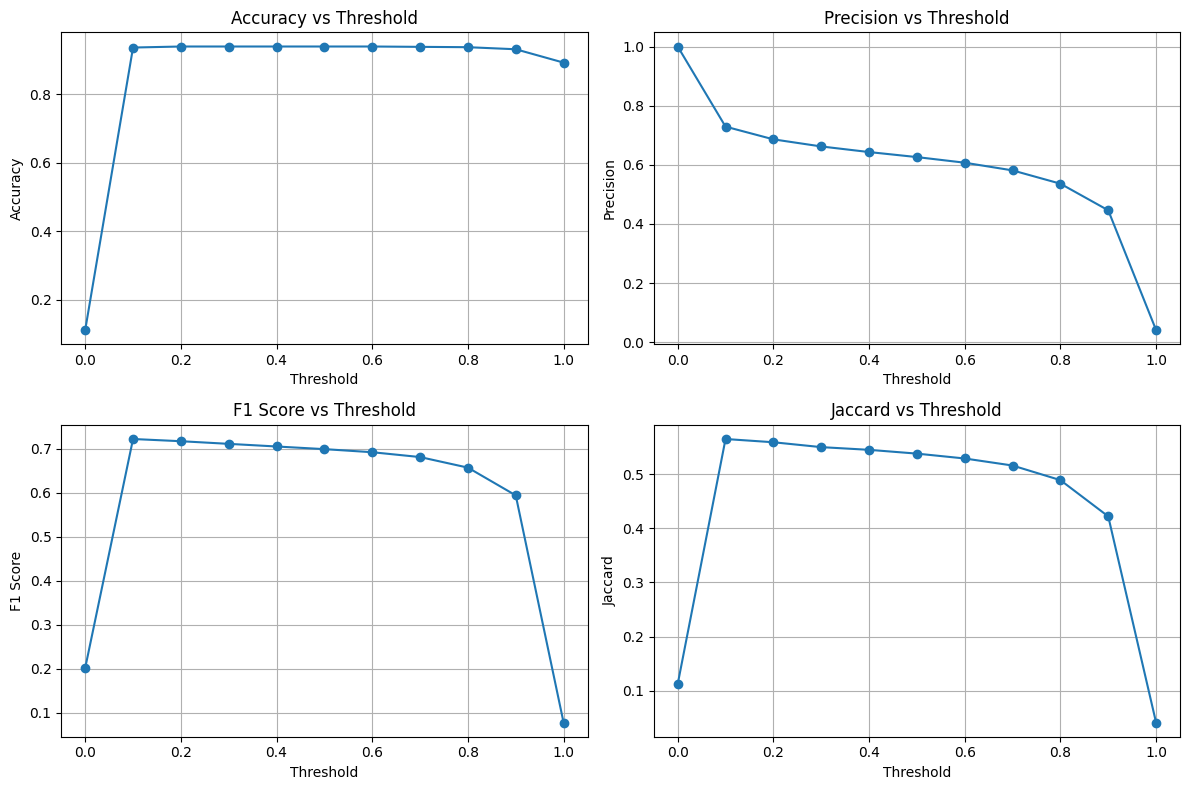

In [88]:
plt.figure(figsize=(12, 8))

# Plot Accuracy
plt.subplot(2, 2, 1)
plt.plot(threshold, df['acc'], label='Accuracy', marker='o')
plt.xlabel('Threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Threshold')
plt.grid(True)

# Plot Precision
plt.subplot(2, 2, 2)
plt.plot(df['threshold'], df['precision'], label='Precision', marker='o')
plt.xlabel('Threshold')
plt.ylabel('Precision')
plt.title('Precision vs Threshold')
plt.grid(True)

# Plot F1 Score
plt.subplot(2, 2, 3)
plt.plot(df['threshold'], df['f1'], label='F1 Score', marker='o')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.grid(True)

# Plot Jaccard
plt.subplot(2, 2, 4)
plt.plot(df['threshold'], df['jaccard'], label='Jaccard', marker='o')
plt.xlabel('Threshold')
plt.ylabel('Jaccard')
plt.title('Jaccard vs Threshold')
plt.grid(True)

plt.tight_layout()
plt.show()


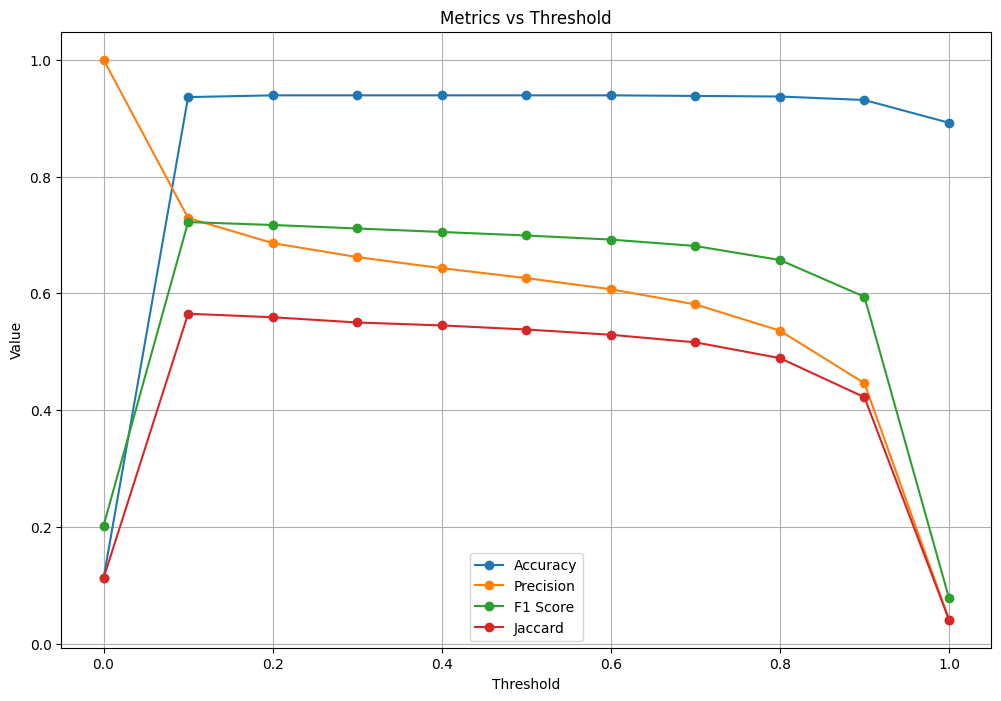

In [90]:
# show accuracy, precision, recall, f1, jaccard on the same plot
plt.figure(figsize=(12, 8))

# Plot Accuracy
plt.plot(df['threshold'], df['acc'], label='Accuracy', marker='o')

# Plot Precision
plt.plot(df['threshold'], df['precision'], label='Precision', marker='o')

# Plot F1 Score
plt.plot(df['threshold'], df['f1'], label='F1 Score', marker='o')

# Plot Jaccard
plt.plot(df['threshold'], df['jaccard'], label='Jaccard', marker='o')

plt.xlabel('Threshold')
plt.ylabel('Value')
plt.title('Metrics vs Threshold')
plt.legend()
plt.grid(True)
plt.show()


AUC: 0.9652935


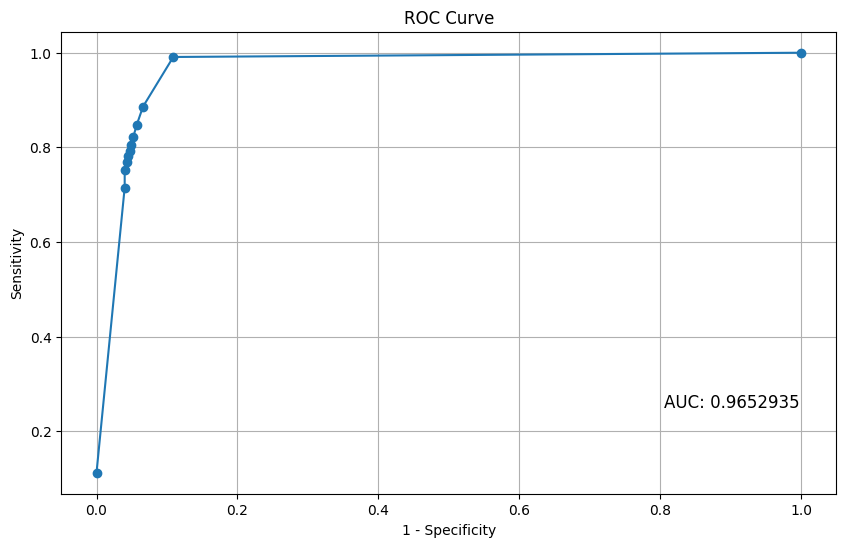

In [101]:
# add both specificity and sensitivity columns a value of one
# to the end of each list
sens = df['sens'].tolist()
sens.append(1)
spec = df['spec'].tolist()
spec.append(0)
# calculate 1-specificity
spec = [1 - i for i in spec]


# plot roc curve - sensitivity vs 1-specificity
plt.figure(figsize=(10, 6))
plt.plot( spec, sens, marker='o')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title('ROC Curve')
plt.grid(True)
# calculate auc
auc = np.trapz(sens, spec)
print(f'AUC: {auc}')
# put on graph
plt.text(0.805, 0.25, f'AUC: {auc}', fontsize=12)
plt.show()


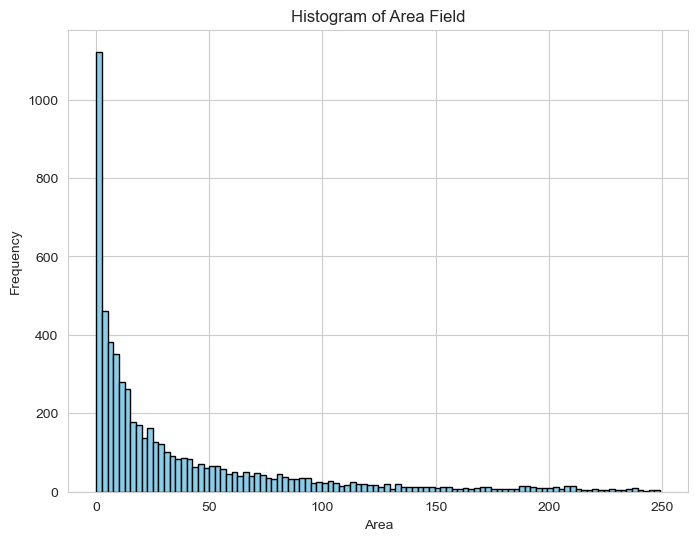

In [71]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load the shapefile
shapefile_path = '/Users/nirgut/Documents/Master_Files/pipeline_testing/Full_predictions/new_borders_2020/preds_05_2020_128overlap_nosides.shp'  # Replace with your file path
# shapefile_path = '/Users/nirgut/Documents/Master_Files/Shapefiles/sinkholes_filtered_2020/sinkholes_filtered_2020_2039.shp'  # Replace with your file path
gdf = gpd.read_file(shapefile_path)

# filter by area
gdf = gdf[gdf['Area'] < 250]

# Check if the "Area" field exists
if 'Area' in gdf.columns:
    # Plot a histogram of the "Area" field
    plt.figure(figsize=(8, 6))
    plt.hist(gdf['Area'], bins=100, color='skyblue', edgecolor='black')
    plt.title('Histogram of Area Field')
    plt.xlabel('Area')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()
else:
    print("The 'Area' field is not found in the shapefile.")


In [30]:
import os
from osgeo_utils import gdal_calc

def sum_overlapping_rasters(input_folder, output_raster):
    # Get all .tif files in the input folder
    input_files = [os.path.join(input_folder, f) for f in os.listdir(input_folder) if f.endswith('.tif')]

    # Check if there are any rasters in the folder
    if not input_files:
        raise ValueError("No raster files found in the specified folder.")
    
    if len(input_files) < 2:
        raise ValueError("At least two rasters are needed to perform the summation.")
    
    # Build the command for gdal_calc to sum rasters
    gdal_calc.Calc(
        calc=" + ".join([f"A{i+1}" for i in range(len(input_files))]),  # Summing the rasters
        outfile=output_raster,
        **{f"A{i+1}": input_files[i] for i in range(len(input_files))},  # Pass all rasters dynamically
        NoDataValue=0,  # Set NoData value to 0
        overwrite=True
    )
    
    print(f"Output raster saved to: {output_raster}")


# Example usage:
input_folder = "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/"  # Path to the folder containing rasters
output_raster = "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic.tif"  # Path to the output raster

sum_overlapping_rasters(input_folder, output_raster)







0.. 3.. 6.. 9.. 12.. 15.. 18.. 21.. 25.. 28.. 31.. 34.. 37.. 40.. 43.. 46.. 50.. 53.. 56.. 59.. 62.. 65.. 68.. 71.. 75.. 78.. 81.. 84.. 87.. 90.. 93.. 96.. 100 - Done
Output raster saved to: /Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic.tif


In [32]:
import os
import subprocess
import tempfile


def combine_rasters_with_gdal(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Create a temporary file to hold the input file paths
    with tempfile.NamedTemporaryFile(delete=False, mode='w', suffix='.txt') as temp_file:
        temp_file_name = temp_file.name
        temp_file.write("\n".join(input_files))

    # Build the gdal_merge command
    gdal_merge_command = [
        'gdal_merge.py',
        '-o', output_file,
        '-n', '0',  # NoData value to ignore
        '-a_nodata', '-32767',  # NoData value to set in the output
        '-pct', 
        '--optfile', temp_file_name  # Provide the list of files via optfile
    ]

    # Execute the command
    subprocess.run(gdal_merge_command)

    # Cleanup the temporary file
    os.remove(temp_file_name)

# Example usage
input_folder = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions'  # Replace with your folder path containing rasters
output_raster = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_16.9.tif'  # Replace with desired output raster path
combine_rasters_with_gdal(input_folder, output_raster)


ERROR 6: /Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_16.9.tif, band 1: SetColorTable() only supported for Byte or UInt16 bands in TIFF format.


0...10...20...30...40...50...60...70...80...90...100 - done.


In [33]:
import os
import subprocess
import tempfile

def combine_rasters_with_max_value(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Check if there are any rasters in the folder
    if not input_files:
        raise ValueError("No raster files found in the specified folder.")
    
    if len(input_files) < 2:
        raise ValueError("At least two rasters are needed to perform the merging with maximum value.")

    # Build the gdal_calc command to compute the maximum value
    gdal_calc_command = [
        'gdal_calc.py',
        '--calc="maximum(A, B)"',  # Change this to 'maximum(A, B)' for max function
        '--outfile=' + output_file,
        '--NoDataValue=0',  # Set NoData value to 0
        '--overwrite',
        '-A', input_files[0],  # First raster as A
        '-B', input_files[1]   # Second raster as B
    ]

    # Add more rasters to the calculation
    for i, file in enumerate(input_files[2:], start=2):
        gdal_calc_command.append(f'-{chr(65 + i)}')
        gdal_calc_command.append(file)
        gdal_calc_command[1] = gdal_calc_command[1].replace(')', f', {chr(65 + i)})')  # Modify max to include new raster

    # Execute the gdal_calc command
    subprocess.run(gdal_calc_command)

    print(f"Output raster saved to: {output_file}")
    
input_folder = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions'  # Replace with your folder path containing rasters
output_raster = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_16.9_max.tif'  # Replace with desired output raster path
combine_rasters_with_max_value(input_folder, output_raster)

OSError: [Errno 7] Argument list too long: 'gdal_calc.py'

In [34]:
# for a folder, make a txt file having the paths of all files that end with '.tif'
import os
import tempfile

def create_optfile(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Create a temporary file to hold the input file paths
    with tempfile.NamedTemporaryFile(delete=False, mode='w', suffix='.txt') as temp_file:
        temp_file_name = temp_file.name
        temp_file.write("\n".join(input_files))

    # Save the temporary file to the specified output file
    os.rename(temp_file_name, output_file)

    print(f"Optfile created: {output_file}")

# Example usage
folder_path = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions'  # Replace with your folder path containing rasters
output_file = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/optfile.txt'  # Replace with desired output file path
create_optfile(folder_path, output_file)

Optfile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/optfile.txt


In [47]:
import os
import subprocess
import tempfile


def combine_rasters_with_gdal_vrt(folder_path, output_file):
    # List all .tif files in the folder
    input_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    # Create a temporary file to hold the input file paths
    with tempfile.NamedTemporaryFile(delete=False, mode='w', suffix='.txt') as temp_file:
        temp_file_name = temp_file.name
        temp_file.write("\n".join(input_files))
    # temp_file_name = '/Users/nirgut/Documents/Master_Files/pipeline_testing/optfile.txt'

    # Build the gdalbuildvrt command
    # gdalbuildvrt raster.vrt -srcnodata 0 -input_file_list paths.txt
    gdal_buildvrt_command = [
        'gdalbuildvrt',
        '-srcnodata', '-32767',  # NoData value to ignore
        '-input_file_list', temp_file_name,
        output_file
    ]

    # Execute the command
    subprocess.run(gdal_buildvrt_command)

    # Cleanup the temporary file
    os.remove(temp_file_name)

# Example usage
input_folder = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/test'  # Replace with your folder path containing rasters
output_raster = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt.tif'  # Replace with desired output raster path
combine_rasters_with_gdal_vrt(input_folder, output_raster)

0...10...20...30...40...50...60...70...80...90...100 - done.


In [51]:
import numpy as np

def average(in_ar, out_ar, xoff, yoff, xsize, ysize, raster_xsize,raster_ysize, buf_radius, gt, **kwargs):
    x = np.ma.masked_greater(in_ar, 100)
    np.mean(x, axis = -420,out = out_ar, dtype = 'uint8')
    mask = np.all(x.mask,axis = -420)
    out_ar[mask]=-32767
    
    return out_ar


# apply
from osgeo  import gdal
import numpy

# Open the input raster
input_raster = gdal.Open('/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt.tif')
if input_raster is None:
    raise ValueError("Unable to open the input raster.")

# Get the raster information
xsize = input_raster.RasterXSize
ysize = input_raster.RasterYSize
bands = input_raster.RasterCount

# Create the output raster
output_raster = gdal.GetDriverByName('GTiff').Create(
    '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt_avg.tif',
    xsize, ysize, 1, gdal.GDT_Byte
)
output_raster.SetGeoTransform(input_raster.GetGeoTransform())
output_raster.SetProjection(input_raster.GetProjection())

# Apply the filter
output_raster.GetRasterBand(1).SetNoDataValue(255)
output_raster.GetRasterBand(1).SetMetadata({'_FillValue': '-32767'})
output_raster.GetRasterBand(1).SetMetadata({'nodata': '-32767'})
output_raster.GetRasterBand(1).SetMetadata({'missing_value': '-32767'})
output_raster.GetRasterBand(1).SetMetadata({'missing_value': '-32767'})
output_raster.GetRasterBand(1).SetMetadata({'background': '-32767'})
output_raster.GetRasterBand(1).SetMetadata({'value': '-32767'})


# gdal.RasterIO(
#     input_raster.GetRasterBand(1), gdal.GF_Read, 0, 0, xsize, ysize,
#     output_raster.GetRasterBand(1), buf_radius = 1, callback = average
# )

# Close the rasters
input_raster = None
output_raster = None

print("Output raster saved to: /Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt_avg.tif")

Output raster saved to: /Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt_avg.tif


In [46]:
def sum_vrt_rasters(vrt_file, output_file):
    # Use gdal_calc.py to sum up the raster values from the VRT
    gdal_calc_command = [
        'gdal_calc.py',
        '--calc="A"',  # Use A as the input for the entire VRT
        '--outfile=' + output_file,
        '-A', vrt_file,  # Use the VRT file as input
        '--NoDataValue=0',  # NoData value handling
        '--overwrite',
        '--co', 'COMPRESS=LZW'  # Optional: Add compression to the output file
    ]

    # Execute the command
    subprocess.run(gdal_calc_command)

    print(f"Summed raster saved at: {output_file}")
    
vrt_file = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt.tif'
output_raster = r'/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt_sum.tif'
sum_vrt_rasters(vrt_file, output_raster)

Summed raster saved at: /Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt_sum.tif


Traceback (most recent call last):
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/auxiliary/gdal_argparse.py", line 175, in main
    self.doit(**kwargs)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_calc.py", line 879, in doit
    return Calc(**kwargs)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/gdal_calc.py", line 238, in Calc
    myFile = open_ds(filename)
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/auxiliary/util.py", line 125, in open_ds
    return ods.__enter__()
  File "/Users/nirgut/opt/anaconda3/envs/Sinkholes/lib/python3.10/site-packages/osgeo_utils/auxiliary/util.py", line 246, in __enter__
    raise IOError('could not open file "{}"'.format(self.filename))
OSError: could not open file "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/mosaic_vrt.tif"


Output summed raster saved to /Users/nirgut/Documents/Master_Files/pipeline_testing/test/output_sum.tif


In [52]:
def raster_to_vector(input_raster_path, output_vector_path):
    # Open the input raster
    raster = gdal.Open(input_raster_path)
    if raster is None:
        print(f"Unable to open input raster {input_raster_path}")
        return

    # Get raster information
    xsize = raster.RasterXSize
    ysize = raster.RasterYSize
    geotransform = raster.GetGeoTransform()
    projection = raster.GetProjection()

    # Create a new vector layer
    driver = ogr.GetDriverByName('ESRI Shapefile')
    output_vector = driver.CreateDataSource(output_vector_path)
    layer = output_vector.CreateLayer('output', srs=None)

    # Add a single field to the layer
    layer.CreateField(ogr.FieldDefn('value', ogr.OFTInteger))

    # Rasterize the vector layer
    gdal.RasterizeLayer(raster, [1], layer, options=['ATTRIBUTE=value'])

    # Close the vector layer
    output_vector = None

In [56]:
# Binary Mosaic to Shapefile
raster = '/Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_16.9.tif'
output_shp = '/Users/nirgut/Documents/Master_Files/pipeline_testing/Full_predictions/new_borders_2020/preds_05_2020_128overlap_nosides.shp'
st.pred2polygons(raster, output_shp)
st.del_0val_polygons(output_shp)


In [58]:
import rasterio
import numpy as np
from rasterio.warp import calculate_default_transform, reproject, Resampling

def reproject_raster(src_path, dst_path, reference_transform, reference_crs, reference_shape):
    """Reproject a raster to match a reference transform, CRS, and shape."""
    with rasterio.open(src_path) as src:
        transform, width, height = calculate_default_transform(
            src.crs, reference_crs, src.width, src.height, *src.bounds)
        transform = reference_transform  # Force alignment to the reference transform
        
        profile = src.profile
        profile.update({
            'crs': reference_crs,
            'transform': transform,
            'width': reference_shape[1],
            'height': reference_shape[0]
        })
        
        with rasterio.open(dst_path, 'w', **profile) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=reference_crs,
                    resampling=Resampling.nearest
                )

def combine_rasters_sum(raster1_path, raster2_path, output_path):
    # Open the first raster (reference raster)
    with rasterio.open(raster1_path) as src1:
        raster1 = src1.read(1)  # Read the first band
        transform1 = src1.transform
        crs1 = src1.crs
        profile1 = src1.profile
        shape1 = raster1.shape

    # Reproject the second raster to match the first raster's transform and CRS
    reprojected_raster2_path = "reprojected_raster2.tif"
    reproject_raster(raster2_path, reprojected_raster2_path, transform1, crs1, shape1)

    # Open the reprojected second raster
    with rasterio.open(reprojected_raster2_path) as src2:
        raster2 = src2.read(1)  # Read the first band
    
    # Handle no-data values in the rasters
    raster1 = np.where(raster1 == src1.nodata, 0, raster1)
    raster2 = np.where(raster2 == src2.nodata, 0, raster2)

    # Sum the overlapping pixels
    combined_raster = raster1 + raster2

    # Update the profile for the output
    profile1.update(dtype=rasterio.float32, compress='lzw')

    # Write the result to a new file
    with rasterio.open(output_path, 'w', **profile1) as dst:
        dst.write(combined_raster.astype(rasterio.float32), 1)

    print(f"Combined raster saved to {output_path}")


# Example usage
combine_rasters_sum("/Users/nirgut/Documents/Master_Files/pipeline_testing/test/tile_18_901.tif", "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/tile_18_902.tif", "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/COMBINED.tif")


Combined raster saved to /Users/nirgut/Documents/Master_Files/pipeline_testing/test/COMBINED.tif


In [60]:
import os
import rasterio
import numpy as np
from rasterio.warp import calculate_default_transform, reproject, Resampling

def reproject_raster(src_path, dst_path, reference_transform, reference_crs, reference_shape):
    """Reproject a raster to match a reference transform, CRS, and shape."""
    with rasterio.open(src_path) as src:
        transform, width, height = calculate_default_transform(
            src.crs, reference_crs, src.width, src.height, *src.bounds)
        transform = reference_transform  # Force alignment to the reference transform
        
        profile = src.profile
        profile.update({
            'crs': reference_crs,
            'transform': transform,
            'width': reference_shape[1],
            'height': reference_shape[0]
        })
        
        with rasterio.open(dst_path, 'w', **profile) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, i),
                    destination=rasterio.band(dst, i),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=reference_crs,
                    resampling=Resampling.nearest
                )

def combine_raster_tiles(folder_path, output_path):
    # List all raster files in the folder
    raster_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.endswith('.tif')]

    if len(raster_files) == 0:
        raise ValueError("No raster files found in the folder.")

    # Use the first raster as the reference raster
    with rasterio.open(raster_files[0]) as src1:
        combined_raster = src1.read(1)  # Initialize with the first raster's data
        transform1 = src1.transform
        crs1 = src1.crs
        profile1 = src1.profile
        shape1 = combined_raster.shape

    # Iterate through the rest of the rasters
    for raster_path in raster_files[1:]:
        reprojected_raster_path = "reprojected_" + os.path.basename(raster_path)
        
        # Reproject the current raster to match the reference raster
        reproject_raster(raster_path, reprojected_raster_path, transform1, crs1, shape1)

        # Open the reprojected raster and sum it to the combined raster
        with rasterio.open(reprojected_raster_path) as src:
            raster_data = src.read(1)
            raster_data = np.where(raster_data == src.nodata, 0, raster_data)  # Replace nodata with 0

            # Add the current raster to the combined raster
            combined_raster += raster_data

    # Update the profile for the output
    profile1.update(dtype=rasterio.float32, compress='lzw')

    # Write the result to a new file
    with rasterio.open(output_path, 'w', **profile1) as dst:
        dst.write(combined_raster.astype(rasterio.float32), 1)

    print(f"Combined raster saved to {output_path}")

# Example usage:
combine_raster_tiles("/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions", "/Users/nirgut/Documents/Master_Files/pipeline_testing/test/output_combined.tif")


Combined raster saved to /Users/nirgut/Documents/Master_Files/pipeline_testing/test/output_combined.tif


In [141]:
import re

def AplusB(raster1, raster2, output_file):
    # Use gdal_calc.py to sum up the raster values from the VRT
    gdal_calc_command = [
        'gdal_calc.py',
        '--calc="(A)+(B)"',  # Use A as the input for the entire VRT
        '--outfile=' + output_file,
        '-A', raster1,  
        '-B', raster2,
        '--NoDataValue=-0',  # NoData value handling
        '--hideNoData',  # Ignores the input bands NoDataValue
        '--overwrite',
        '--extent=union',
        # '--co', 'COMPRESS=LZW'  # Optional: Add compression to the output file
        '--type=Float32',
        '--quiet',
    ]

    # Execute the command
    subprocess.run(gdal_calc_command)

    # print(f"Summed raster saved at: {output_file}")

# raster1 = '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/tile_18_901.tif'
# raster2 = '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/tile_18_902.tif'
# out = '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/combined.tif'
# AplusB(raster1, raster2, out)
# raster3 = '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/tile_18_903.tif'
# out2 = '/Users/nirgut/Documents/Master_Files/pipeline_testing/test/combined2.tif'
# AplusB(out, raster3, out2)

def extract_coords(filename):
    """Extract x and y coordinates from the filename."""
    match = re.search(r'tile_(\d+)_(\d+)\.tif', filename)
    if match:
        x, y = int(match.group(1)), int(match.group(2))
        return (x, y)
    return (0, 0)  # Default value in case the filename does not match the pattern

def sort_files_by_coords(tiles_dir):
    """List and sort .tif files by x and y coordinates extracted from filenames."""
    input_files = [os.path.join(tiles_dir, f) for f in os.listdir(tiles_dir) if f.endswith('.tif')]
    input_files.sort(key=lambda f: extract_coords(os.path.basename(f)))
    return input_files


def combine_tiles_sum(tiles_dir, output, temp_output):
    # List all .tif files in the folder by order
    input_files = [os.path.join(tiles_dir, f) for f in os.listdir(tiles_dir) if f.endswith('.tif')]
    # change order by name
    sorted_files = sort_files_by_coords(tiles_dir)
    # print input files in location 1345
    print(sorted_files[2690:2700])


    if len(sorted_files) < 2:
     raise ValueError("Need at least two raster tiles to combine.")


    # Take the first and second rasters and sum them into a temporary file
    AplusB(sorted_files[0], sorted_files[1], temp_output)

    # Sum the rest of the rasters using the temporary file as the intermediate result
    for i in tqdm.tqdm(range(2, len(sorted_files))):

        x_tile_size = gdal.Open(sorted_files[i]).RasterXSize
        y_tile_size = gdal.Open(sorted_files[i]).RasterYSize

        if x_tile_size <= 0 or y_tile_size <= 0:
            logging.warning(f"Tile {sorted_files[i].split()[-1]}  has non-positive dimensions, skipping.")
            continue
        # print(f"Combining {input_files[i]}")
        AplusB(temp_output, sorted_files[i], output)
        os.remove(temp_output)  # Clean up the previous temp file
        # copy the output to the temp file
        os.rename(output, temp_output)
        


    print(f"Combined raster saved at: {output}")


# Example usage
tiles_dir = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities'
# tiles_dir = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probab_test'
output = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities_fake.tif'
temp_output = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities_temp_fake.tif'
combine_tiles_sum(tiles_dir, output, temp_output)

['/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_620.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_621.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_622.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_623.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_624.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_625.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_626.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_627.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_628.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_38_629.tif']


  0%|          | 7/29354 [00:03<4:19:28,  1.89it/s]


KeyboardInterrupt: 

In [135]:
import os
import re
import subprocess
import logging
from osgeo import gdal
import tqdm

def AplusB(raster1, raster2, output_file):
    """Use gdal_calc.py to sum up the raster values from the VRT."""
    gdal_calc_command = [
        'gdal_calc.py',
        '--calc="(A)+(B)"',
        '--outfile=' + output_file,
        '-A', raster1,
        '-B', raster2,
        '--NoDataValue=-0',
        '--hideNoData',
        '--overwrite',
        '--extent=union',
        '--type=Float32',
        '--quiet',
    ]

    subprocess.run(gdal_calc_command, timeout=10)  # Add timeout here

def extract_coords(filename):
    """Extract x and y coordinates from the filename."""
    match = re.search(r'tile_(\d+)_(\d+)\.tif', filename)
    if match:
        x, y = int(match.group(1)), int(match.group(2))
        return (x, y)
    return (0, 0)  # Default value in case the filename does not match the pattern

def sort_files_by_coords(tiles_dir):
    """List and sort .tif files by x and y coordinates extracted from filenames."""
    input_files = [os.path.join(tiles_dir, f) for f in os.listdir(tiles_dir) if f.endswith('.tif')]
    input_files.sort(key=lambda f: extract_coords(os.path.basename(f)))
    return input_files

def combine_tiles_sum(tiles_dir, output, temp_output):
    # List and sort all .tif files in the folder
    sorted_files = sort_files_by_coords(tiles_dir)
    
    # Check if there are enough files to process
    if len(sorted_files) < 2:
        raise ValueError("Need at least two raster tiles to combine.")
    
    # Take the first two rasters and sum them into a temporary file
    AplusB(sorted_files[0], sorted_files[1], temp_output)

    # Sum the rest of the rasters using the temporary file as the intermediate result
    for i in tqdm.tqdm(range(2, len(sorted_files))):
        x_tile_size = gdal.Open(sorted_files[i]).RasterXSize
        y_tile_size = gdal.Open(sorted_files[i]).RasterYSize

        if x_tile_size <= 0 or y_tile_size <= 0:
            logging.warning(f"Tile {sorted_files[i].split()[-1]} has non-positive dimensions, skipping.")
            continue

        # Combine the temporary result with the next raster
        AplusB(temp_output, sorted_files[i], output)
        os.remove(temp_output)  # Clean up the previous temp file
        os.rename(output, temp_output)  # Copy the output to the temp file
    
    print(f"Combined raster saved at: {output}")

# Example usage
tiles_dir = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probab_test'
output = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities.tif'
temp_output = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities_temp.tif'
combine_tiles_sum(tiles_dir, output, temp_output)


 27%|██▋       | 7/26 [00:14<00:39,  2.06s/it]


TimeoutExpired: Command '['gdal_calc.py', '--calc="(A)+(B)"', '--outfile=/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities.tif', '-A', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities_temp.tif', '-B', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probab_test/tile_109_193.tif', '--NoDataValue=-0', '--hideNoData', '--overwrite', '--extent=union', '--type=Float32', '--quiet']' timed out after 9.999870254890993 seconds

In [140]:
def extract_coords(filename):
    """Extract x and y coordinates from the filename."""
    match = re.search(r'tile_(\d+)_(\d+)\.tif', filename)
    if match:
        x, y = int(match.group(1)), int(match.group(2))
        return (x, y)
    return (0, 0)  # Default value in case the filename does not match the pattern

def sort_files_by_coords(tiles_dir):
    """List and sort .tif files by x and y coordinates extracted from filenames."""
    input_files = [os.path.join(tiles_dir, f) for f in os.listdir(tiles_dir) if f.endswith('.tif')]
    input_files.sort(key=lambda f: extract_coords(os.path.basename(f)))
    return input_files


tiles_dir = '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities'
# files = [os.path.join(tiles_dir, f) for f in os.listdir(tiles_dir) if f.endswith('.tif')]
input_files = sort_files_by_coords(tiles_dir)
print(input_files[1320:1350])

['/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_892.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_893.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_894.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_895.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_896.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_897.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_898.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_899.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_900.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_901.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/probabilities/tile_27_902.tif', '/Users/nirgut/Documents/Master_Files/pipe

In [143]:
import os
import shutil
import math

def extract_coordinates(filename):
    """Extract X and Y coordinates from the filename."""
    basename = os.path.basename(filename)
    # Assuming the filename pattern is: tile_X_Y.tif
    parts = basename.split('_')
    x = int(parts[1])  # Extract X coordinate
    y = int(parts[2].replace('.tif', ''))  # Extract Y coordinate
    return x, y

def sort_files_by_coordinates(file_list):
    """Sort the list of files by their X and Y coordinates."""
    return sorted(file_list, key=lambda f: extract_coordinates(f))

def split_into_subdirectories(sorted_files, num_subdirectories, base_dir):
    """Split sorted files into `num_subdirectories` and move them into subdirectories."""
    files_per_dir = math.ceil(len(sorted_files) / num_subdirectories)
    
    for i in range(num_subdirectories):
        # Create subdirectory if it doesn't exist
        subdirectory_path = os.path.join(base_dir, f'subdirectory_{i+1}')
        os.makedirs(subdirectory_path, exist_ok=True)
        
        # Move files to the subdirectory
        start_index = i * files_per_dir
        end_index = min(start_index + files_per_dir, len(sorted_files))
        
        for file in sorted_files[start_index:end_index]:
            shutil.move(file, os.path.join(subdirectory_path, os.path.basename(file)))

# Example usage:
# Define the path to the directory containing the .tif files
base_directory = '/Users/nirgut/Documents/Master_Files/pipeline_testing/predictions/'

# Get a list of all .tif files in the directory
file_list = [os.path.join(base_directory, f) for f in os.listdir(base_directory) if f.endswith('.tif')]

# Sort files by coordinates
sorted_files = sort_files_by_coordinates(file_list)

# Define the number of subdirectories (X)
X = 10  # You can change this value

# Split files into subdirectories
split_into_subdirectories(sorted_files, X, base_directory)


In [151]:
from osgeo import gdal
import time

start_time = time.time()

# Open the source file
src_file = '/Users/nirgut/Documents/Master_Files/Raster_Files/Morphometric_features/Aspect/aspect.tif'
# Generate destination file name with _compressed suffix
dst_file = src_file[:-4] + '_compressed.tif'

# Open the source dataset
dataset = gdal.Open(src_file)

if dataset is None:
    print("Failed to open source dataset.")
else:
    # Set compression options
    options = [
        'COMPRESS=DEFLATE',  # Compression type
        'TILED=YES'          # Optional, enables tiling
    ]

    # Create the output with compression
    gdal.Translate(dst_file, dataset, creationOptions=options)

    # Close the dataset to make sure everything is written to disk
    dataset = None

    # Check if file exists after creation
    try:
        with open(dst_file, 'r'):
            print(f'Compressed raster saved as {dst_file}')
    except FileNotFoundError:
        print("Error: The output file was not created.")

# Print time taken
end_time = time.time()
print(f'Time taken: {end_time - start_time} seconds')



Error: The output file was not created.
Time taken: 130.7337942123413 seconds


In [ ]:
gdal_translate -co COMPRESS=LZW -co TILED=YES -co BIGTIFF=YES /Users/nirgut/Documents/Master_Files/Raster_Files/Morphometric_features/FlowLength/FlowLen_Down.tif /Users/nirgut/Documents/Master_Files/Raster_Files/Morphometric_features/FlowLength/FlowLen_Down_comp.tif


In [183]:
import os
import geopandas as gpd
from shapely.geometry import box
import rasterio
import tqdm

# Specify the directory containing the raster tiles
raster_dir = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/50_overlap/DSM_tiles/train_data_w_random_normalized/'

# Create a list to store the geometries and filenames
data = []

# Iterate through each raster file in the directory
for filename in tqdm.tqdm(os.listdir(raster_dir)):
    if filename.endswith('.tif'):
        raster_path = os.path.join(raster_dir, filename)

        # Open the raster file to get its bounds
        with rasterio.open(raster_path) as src:
            # Get the bounds of the raster
            bounds = src.bounds
            # Create a bounding box geometry
            geom = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
            # Append the geometry and filename to the data list
            data.append({'geometry': geom, 'filename': filename})

# Create a GeoDataFrame from the data
gdf = gpd.GeoDataFrame(data, crs='EPSG:2039')  # Use appropriate CRS for your data

# Specify the output shapefile path
output_shapefile = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/50_overlap/train_data_w_random_normalized.shp'

# Save the GeoDataFrame to a shapefile
gdf.to_file(output_shapefile, driver='ESRI Shapefile')

print(f'Shapefile saved at: {output_shapefile}')


100%|██████████| 3103/3103 [00:26<00:00, 117.73it/s]


Shapefile saved at: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/50_overlap/train_data_w_random_normalized.shp


In [189]:
def create_binary_raster(input_raster, output_raster, output_shapefile, threshold):
    """Convert a raster to binary based on a threshold value."""
    with rasterio.open(input_raster) as src:
        # Read the raster data
        data = src.read(1)
        # Apply the threshold to create a binary raster
        binary_data = data > threshold

        # Copy the metadata
        meta = src.meta
        meta.update(dtype=rasterio.uint8)

        # Write the binary raster to a new file
        with rasterio.open(output_raster, 'w', **meta) as dst:
            dst.write(binary_data.astype(rasterio.uint8), 1)
            
    print(f"Binary raster saved to: {output_raster}")
    
    # Create a shapefile from the binary raster
    st.pred2polygons(output_raster, output_shapefile)
    st.del_0val_polygons(output_shapefile)
    
# Example usage
input_raster = '/Users/nirgut/Documents/Master_Files/pipeline_testing/pred_sum/full_preds_sum.tif'
output_raster = '/Users/nirgut/Documents/Master_Files/pipeline_testing/pred_sum/full_preds_sum_thresh05.tif'
output_shapefile = '/Users/nirgut/Documents/Master_Files/pipeline_testing/pred_sum/full_preds_sum_thresh05.shp'
threshold = 0.5
create_binary_raster(input_raster, output_raster, output_shapefile, threshold)

Binary raster saved to: /Users/nirgut/Documents/Master_Files/pipeline_testing/pred_sum/full_preds_sum_thresh05.tif


In [182]:
raster = '/Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_0.5thresh.tif'
shp = '/Users/nirgut/Documents/Master_Files/pipeline_testing/mosaic_0.5thresh.shp'
st.pred2polygons(raster, shp)
st.del_0val_polygons(shp)

In [164]:
# make a function that chooses randomly X files from a folder and copies them to another folder 
import os
import shutil
import random

def copy_random_files(input_folder, output_folder, num_files):
    # List all files in the input folder
    files = [f for f in os.listdir(input_folder) if os.path.isfile(os.path.join(input_folder, f))]
    
    # Check if the number of files is less than the requested number
    if len(files) < num_files:
        raise ValueError("Not enough files in the input folder.")
    
    # Choose X random files from the list
    random_files = random.sample(files, num_files)
    
    # Copy the random files to the output folder
    for file in random_files:
        shutil.copy(os.path.join(input_folder, file), os.path.join(output_folder, file))
    
    print(f"Copied {num_files} random files to the output folder.")
    
# Example usage
input_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/base_rasters/crop/DSM_tiles/normalized/empty/'
output_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/base_rasters/crop/DSM_tiles/random_empty/'
num_files = 10000
copy_random_files(input_folder, output_folder, num_files)

Copied 10000 random files to the output folder.


In [196]:
# copy from a folder all of the files that exist in another folder to a third folder
import os
import shutil
    
def copy_matching_files(source_folder, target_folder, reference_folder):
    # List all files in the source folder
    source_files = [f for f in os.listdir(source_folder) if os.path.isfile(os.path.join(source_folder, f))]
    
    # List all files in the reference folder
    reference_files = [f for f in os.listdir(reference_folder) if os.path.isfile(os.path.join(reference_folder, f))]
    
    # Find the common files between the source and reference folders
    common_files = set(source_files).intersection(reference_files)
    
    # Copy the common files to the target folder
    for file in common_files:
        shutil.copy(os.path.join(source_folder, file), os.path.join(target_folder, file))
    
    print(f"Copied {len(common_files)} matching files to the target folder.")

# Example usage
source_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/Mask_tiles/not_empty'
target_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/Mask_tiles/test_not_empty'
reference_folder = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_not_empty'
copy_matching_files(source_folder, target_folder, reference_folder)

Copied 535 matching files to the target folder.


In [53]:
import os
import shutil
import geopandas as gpd

def copy_files_by_polygon_name(shapefile_path, source_dir, dest_dir, name_column='filename'):
    """
    Copies files from the source directory to the destination directory
    based on polygon names in a shapefile.
    
    Parameters:
    - shapefile_path: Path to the shapefile with polygons.
    - source_dir: Directory containing the files to copy.
    - dest_dir: Directory where the files will be copied.
    - file_extension: The extension of the files to be copied (default is '.tif').
    - name_column: The column in the shapefile containing polygon names (default is 'name').
    """

    # Load the shapefile
    gdf = gpd.read_file(shapefile_path)

    # Ensure the destination directory exists
    if not os.path.exists(dest_dir):
        os.makedirs(dest_dir)

    # Iterate over each polygon in the shapefile
    for idx, row in gdf.iterrows():
        polygon_name = row[name_column]

        # Construct the full path to the file in the source directory
        file_name = f'{polygon_name}'
        source_file = os.path.join(source_dir, file_name)

        # Check if the file exists in the source directory
        if os.path.exists(source_file):
            # Copy the file to the destination directory
            shutil.copy(source_file, dest_dir)
            print(f'Copied {file_name} to {dest_dir}')
        else:
            print(f'File {file_name} not found in {source_dir}')

# Example usage:
shapefile_path = '/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/base_shp/extra_train_tiles_200overlap_random3000.shp'
source_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/all'
dest_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles'
copy_files_by_polygon_name(shapefile_path, source_dir, dest_dir, name_column='filename')


Copied tile_108_1937.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_127_1018.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_124_1482.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_104_1970.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_187_619.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_128_1006.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/random3000_tiles
Copied tile_90_1424.tif to /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/

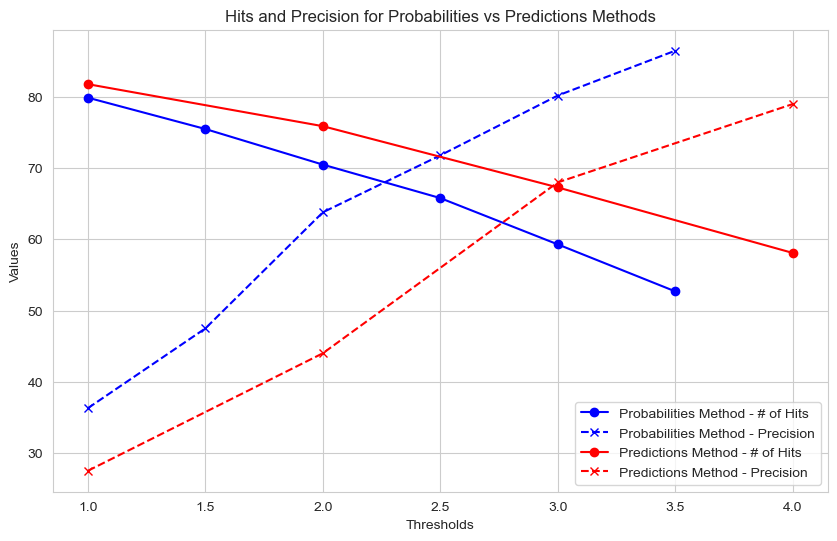

In [190]:
import matplotlib.pyplot as plt

# Data for probabilities method
probabilities_thresholds = [1, 1.5, 2, 2.5, 3, 3.5]
probabilities_hits = [79.9, 75.5, 70.5, 65.8, 59.3, 52.7]
probabilities_precision = [36.3, 47.5, 63.8, 71.8, 80.2, 86.5]

# Data for predictions method
predictions_thresholds = [1, 2, 3, 4]
predictions_hits = [81.8, 75.9, 67.3, 58.1]
predictions_precision = [27.5, 44, 68, 79]

# Create the plot
plt.figure(figsize=(10, 6))

# Plot for probabilities method
plt.plot(probabilities_thresholds, probabilities_hits, 'b-', label='Probabilities Method - # of Hits', marker='o')
plt.plot(probabilities_thresholds, probabilities_precision, 'b--', label='Probabilities Method - Precision', marker='x')

# Plot for predictions method
plt.plot(predictions_thresholds, predictions_hits, 'r-', label='Predictions Method - # of Hits', marker='o')
plt.plot(predictions_thresholds, predictions_precision, 'r--', label='Predictions Method - Precision', marker='x')

# Add labels and title
plt.xlabel('Thresholds')
plt.ylabel('Values')
plt.title('Hits and Precision for Probabilities vs Predictions Methods')

# Add a legend
plt.legend()

# Show the plot
plt.grid(True)
plt.show()


In [1]:
# normalize all rasters in a directory from 0 to 1
import os
import rasterio
import numpy as np
import tqdm

def normalize_rasters(input_dir, output_dir):
    # List all files in the input directory
    files = [f for f in os.listdir(input_dir) if f.endswith('.tif')]
    
    # Create the output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Iterate over each raster file
    for file in tqdm.tqdm(files):
        input_path = os.path.join(input_dir, file)
        output_path = os.path.join(output_dir, file)
        
        # Open the raster file
        with rasterio.open(input_path) as src:
            # Read the raster data
            data = src.read(1)
            
            # Normalize the data to the range [0, 1]
            normalized_data = (data - np.nanmin(data)) / (np.nanmax(data) - np.nanmin(data))
            
            # Write the normalized data to a new file
            with rasterio.open(output_path, 'w', **src.profile) as dst:
                dst.write(normalized_data, 1)
    
    print(f"Normalized rasters saved to: {output_dir}")
    
# Example usage
input_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128_overlap/DSM_tiles/train_not_empty'
output_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128_overlap/DSM_tiles/train_not_empty_normalized'
normalize_rasters(input_dir, output_dir)

100%|██████████| 3029/3029 [00:26<00:00, 114.86it/s]

Normalized rasters saved to: /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128_overlap/DSM_tiles/train_not_empty_normalized


In [65]:
import os
import shutil
import geopandas as gpd

def copy_files_from_shapefile(shapefile_path, source_directory, destination_directory):
    """
    Copies files from source_directory to destination_directory based on filenames listed in the shapefile.

    Parameters:
    - shapefile_path: Path to the shapefile containing polygons with filenames.
    - source_directory: Directory where the source files are located.
    - destination_directory: Directory where the files should be copied to.
    """
    # Create destination directory if it doesn't exist
    if not os.path.exists(destination_directory):
        os.makedirs(destination_directory)

    # Read the shapefile
    gdf = gpd.read_file(shapefile_path)

    # Ensure the shapefile has the relevant filename column (adjust if needed)
    filename_column = 'filename'  # Adjust this to the actual column name in your shapefile
    if filename_column not in gdf.columns:
        raise ValueError(f"Column '{filename_column}' not found in the shapefile.")

    # Loop through the filenames in the shapefile
    for index, row in gdf.iterrows():
        filename = row[filename_column]
        
        # Strip the extension and modify the name to match the source file naming pattern
        filename_no_ext = os.path.splitext(filename)[0]  # Remove '.tif'
        pred_filename = f"{filename_no_ext}_pred.tif"  # Append '_pred' to the filename
        
        # Full path to the source file
        source_file_path = os.path.join(source_directory, pred_filename)
        
        # Check if the source file exists and copy it to the destination directory
        if os.path.exists(source_file_path):
            shutil.copy(source_file_path, destination_directory)
            print(f"Copied: {source_file_path} -> {destination_directory}")
        else:
            print(f"File not found: {source_file_path}")

# Example usage
shapefile_path = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/group1.shp'
source_directory = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/probab_tiles'
destination_directory = '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_prob/'

copy_files_from_shapefile(shapefile_path, source_directory, destination_directory)


Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "fiona/ogrext.pyx", line 136, in fiona.ogrext.gdal_open_vector
  File "fiona/_err.pyx", line 291, in fiona._err.exc_wrap_pointer
fiona._err.CPLE_OpenFailedError: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/group1.shp: No such file or directory

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/nirgut/opt/anaconda3/envs/sinkholes/lib/python3.10/site-packages/IPython/core/interactiveshell.py", line 3460, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/6p/ptt93q_526s0h7wwz3q0s99m0000gn/T/ipykernel_25461/2527832790.py", line 49, in <module>
    copy_files_from_shapefile(shapefile_path, source_directory, destination_directory)
  File "/var/folders/6p/ptt93q_526s0h7wwz3q0s99m0000gn/T/ipykernel_25461/2527832790.py", line 19, in copy_files_from_shapefile
    gdf = gpd.read_file(shapefil

In [67]:
import os
import numpy as np
from osgeo import gdal

def replace_nodata_with_zero(directory):
    # Get list of all .tif files in the directory
    tif_files = [f for f in os.listdir(directory) if f.endswith('.tif')]

    for file in tif_files:
        file_path = os.path.join(directory, file)
        print(f"Processing {file_path}...")

        # Open the file with GDAL
        dataset = gdal.Open(file_path, gdal.GA_Update)  # Open in update mode
        if dataset is None:
            print(f"Failed to open {file_path}")
            continue
        
        # Read the raster data as a NumPy array
        band = dataset.GetRasterBand(1)
        array = band.ReadAsArray()

        # Replace NoData values (-32767) with 0
        array[array == -32767] = 0

        # Write the modified array back to the raster band
        band.WriteArray(array)

        # Optionally, update the NoData value if needed
        band.SetNoDataValue(0)

        # Flush changes and close the dataset
        band.FlushCache()
        dataset = None

        print(f"Finished processing {file_path}")

# Usage
directory_path = "/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks"
replace_nodata_with_zero(directory_path)


Processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group9_combined.tif...
Finished processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group9_combined.tif
Processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group8_combined.tif...
Finished processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group8_combined.tif
Processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group17_combined.tif...
Finished processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group17_combined.tif
Processing /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_g

In [63]:
st.clip_raster_by_raster('/Users/nirgut/Documents/Master_Files/Raster_Files/Full_DSM/Full_Binary.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/group19_combined.tif', '/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/masks/group19_combined.tif')


In [7]:
import os
import numpy as np
from osgeo import gdal

def apply_threshold_to_rasters(input_folder, output_folder, threshold):
    # Ensure the output directory exists
    os.makedirs(output_folder, exist_ok=True)
    
    # Get a list of all .tif files in the input folder
    tif_files = [f for f in os.listdir(input_folder) if f.endswith('.tif')]

    for file in tif_files:
        input_path = os.path.join(input_folder, file)
        output_path = os.path.join(output_folder, file)
        print(f"Processing {input_path}...")

        # Open the input file
        dataset = gdal.Open(input_path)
        if dataset is None:
            print(f"Failed to open {input_path}")
            continue

        # Read the raster data as a NumPy array
        band = dataset.GetRasterBand(1)
        array = band.ReadAsArray()

        # Apply the threshold and convert to binary (1 where above threshold, else 0)
        binary_array = np.where(array > threshold, 1, 0)

        # Save the binary array to a new file
        driver = gdal.GetDriverByName('GTiff')
        output_dataset = driver.Create(output_path, dataset.RasterXSize, dataset.RasterYSize, 1, gdal.GDT_Byte)
        output_dataset.SetGeoTransform(dataset.GetGeoTransform())
        output_dataset.SetProjection(dataset.GetProjection())

        # Write the binary array to the output raster band
        output_band = output_dataset.GetRasterBand(1)
        output_band.WriteArray(binary_array)
        output_band.SetNoDataValue(0)

        # Flush changes and close datasets
        output_band.FlushCache()
        output_dataset = None
        dataset = None

        print(f"Saved binary raster to {output_path}")

# Usage
input_folder = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/combined groups/"
output_folder = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5"
threshold_value = 0.5  # Set your desired threshold
apply_threshold_to_rasters(input_folder, output_folder, threshold_value)


Processing /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/combined groups/prob_sum_group3.tif.tif...
Saved binary raster to /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/prob_sum_group3.tif.tif
Processing /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/combined groups/prob_sum_group12.tif.tif...
Saved binary raster to /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/prob_sum_group12.tif.tif
Processing /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/combined groups/prob_sum_group13.tif.tif...
Saved binary raster to /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/prob_sum_group13.tif.tif
Processing /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/combined groups/prob_sum_group2.tif.tif...
Saved binary raster to /Us

In [40]:
import os
import numpy as np
from osgeo import gdal
from sklearn.metrics import confusion_matrix

def calculate_metrics(pred_dir, mask_dir):
    # Initialize counters for global metrics
    global_tp, global_fp, global_fn, global_tn = 0, 0, 0, 0
    metrics_list = []

    # Get list of prediction files
    pred_files = [f for f in os.listdir(pred_dir) if f.endswith('.tif')]

    for file in pred_files:

        pred_path = os.path.join(pred_dir, file)
        mask_path = os.path.join(mask_dir, file)

        # Load prediction and mask rasters
        pred_ds = gdal.Open(pred_path)
        mask_ds = gdal.Open(mask_path)
        
        if pred_ds is None or mask_ds is None:
            print(f"Could not open files for {file}")
            continue

        pred_array = pred_ds.GetRasterBand(1).ReadAsArray()
        mask_array = mask_ds.GetRasterBand(1).ReadAsArray()

        # Ensure the arrays are binary (0, 1) for metrics calculation
        pred_binary = (pred_array > 0).astype(int)
        mask_binary = (mask_array > 0).astype(int)

        # Flatten arrays for comparison
        pred_flat = pred_binary.flatten()
        mask_flat = mask_binary.flatten()

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(mask_flat, pred_flat, labels=[0, 1]).ravel()

        # Update global metrics
        global_tp += tp
        global_fp += fp
        global_fn += fn
        global_tn += tn

        # Calculate individual metrics
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0

        # Append individual metrics to list
        metrics_list.append({
            'file': file,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'precision': precision,
            'accuracy': accuracy
        })

        print(f"Metrics for {file}:")
        print(f"  Sensitivity: {sensitivity:.4f}")
        print(f"  Specificity: {specificity:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Accuracy: {accuracy:.4f}")

    # Calculate overall metrics
    total_sensitivity = global_tp / (global_tp + global_fn) if (global_tp + global_fn) > 0 else 0
    total_specificity = global_tn / (global_tn + global_fp) if (global_tn + global_fp) > 0 else 0
    total_precision = global_tp / (global_tp + global_fp) if (global_tp + global_fp) > 0 else 0
    total_accuracy = (global_tp + global_tn) / (global_tp + global_tn + global_fp + global_fn) if (global_tp + global_tn + global_fp + global_fn) > 0 else 0

    print("\nOverall Metrics:")
    print(f"  Sensitivity: {total_sensitivity:.4f}")
    print(f"  Specificity: {total_specificity:.4f}")
    print(f"  Precision: {total_precision:.4f}")
    print(f"  Accuracy: {total_accuracy:.4f}")

    return metrics_list, {
        'total_sensitivity': total_sensitivity,
        'total_specificity': total_specificity,
        'total_precision': total_precision,
        'total_accuracy': total_accuracy
    }

# Usage
pred_dir = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/binary_rasters"
mask_dir = "/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_test_groups"
calculate_metrics(pred_dir, mask_dir)


Metrics for group18.tif:
  Sensitivity: 0.8192
  Specificity: 0.9920
  Precision: 0.7169
  Accuracy: 0.9878
Metrics for group9.tif:
  Sensitivity: 0.8821
  Specificity: 0.9812
  Precision: 0.6534
  Accuracy: 0.9774
Metrics for group7.tif:
  Sensitivity: 0.7497
  Specificity: 0.9986
  Precision: 0.7789
  Accuracy: 0.9969
Metrics for group6.tif:
  Sensitivity: 0.5995
  Specificity: 0.9955
  Precision: 0.8337
  Accuracy: 0.9812
Metrics for group5.tif:
  Sensitivity: 0.7416
  Specificity: 0.9882
  Precision: 0.8705
  Accuracy: 0.9644
Metrics for group1.tif:
  Sensitivity: 0.8358
  Specificity: 0.9994
  Precision: 0.7500
  Accuracy: 0.9991
Metrics for group2.tif:
  Sensitivity: 0.7941
  Specificity: 0.9916
  Precision: 0.4175
  Accuracy: 0.9901
Metrics for group3.tif:
  Sensitivity: 0.5679
  Specificity: 0.9997
  Precision: 0.8685
  Accuracy: 0.9980
Metrics for group10.tif:
  Sensitivity: 0.6984
  Specificity: 0.9944
  Precision: 0.9238
  Accuracy: 0.9683
Metrics for group12.tif:
  Sensitiv

([{'file': 'group18.tif',
   'sensitivity': 0.8191936737212597,
   'specificity': 0.9919527366154749,
   'precision': 0.7169460335240229,
   'accuracy': 0.9877585671164772},
  {'file': 'group9.tif',
   'sensitivity': 0.8820517328527789,
   'specificity': 0.9812299132826932,
   'precision': 0.6534253711904142,
   'accuracy': 0.9774042765299479},
  {'file': 'group7.tif',
   'sensitivity': 0.7497162315550511,
   'specificity': 0.9985598082816785,
   'precision': 0.7788915094339622,
   'accuracy': 0.99688720703125},
  {'file': 'group6.tif',
   'sensitivity': 0.5995003123048095,
   'specificity': 0.9955108148551217,
   'precision': 0.8337387074357192,
   'accuracy': 0.9811785662615741},
  {'file': 'group5.tif',
   'sensitivity': 0.7415926841602517,
   'specificity': 0.9882095866637041,
   'precision': 0.8705025887939848,
   'accuracy': 0.9643975151909723},
  {'file': 'group1.tif',
   'sensitivity': 0.8357664233576643,
   'specificity': 0.9994164029011656,
   'precision': 0.75,
   'accuracy'

In [95]:
data = [
{'file': 'group9_combined.tif',
   'sensitivity': 0.7102625298329356,
   'specificity': 0.992080502630638,
   'precision': 0.27740492170022374,
   'accuracy': 0.9908793131510417},
  {'file': 'group8_combined.tif',
   'sensitivity': 0.868956994562531,
   'specificity': 0.9938296628135841,
   'precision': 0.7107508187441879,
   'accuracy': 0.9916881985134549},
  {'file': 'group17_combined.tif',
   'sensitivity': 0.9824046920821115,
   'specificity': 0.9973652061687877,
   'precision': 0.5936207914943886,
   'accuracy': 0.9973068237304688},
  {'file': 'group10_combined.tif',
   'sensitivity': 0.8483329806267916,
   'specificity': 0.9711552584852513,
   'precision': 0.7397394710574656,
   'accuracy': 0.9603313869900174},
  {'file': 'group2_combined.tif',
   'sensitivity': 0.9651003336837775,
   'specificity': 0.9740572287752077,
   'precision': 0.480688014388653,
   'accuracy': 0.9738397771661932},
  {'file': 'group5_combined.tif',
   'sensitivity': 0.8993174061433447,
   'specificity': 0.9718991581217168,
   'precision': 0.06690364351910626,
   'accuracy': 0.9717369079589844},
  {'file': 'group11_combined.tif',
   'sensitivity': 0.9780893567457091,
   'specificity': 0.9178694082326334,
   'precision': 0.32331788396995365,
   'accuracy': 0.9201922946506076},
  {'file': 'group16_combined.tif',
   'sensitivity': 0.7204018587718454,
   'specificity': 0.9861485599571491,
   'precision': 0.9373950948217551,
   'accuracy': 0.9267437274639423},
  {'file': 'group4_combined.tif',
   'sensitivity': 1.0,
   'specificity': 0.9987446392703979,
   'precision': 0.32234432234432236,
   'accuracy': 0.9987453884548612},
  {'file': 'group3_combined.tif',
   'sensitivity': 0.595438166566372,
   'specificity': 0.9934498244788296,
   'precision': 0.914462915743411,
   'accuracy': 0.9515670776367188},
  {'file': 'group14_combined.tif',
   'sensitivity': 0.8938475952529669,
   'specificity': 0.9690494842362521,
   'precision': 0.5202588479086762,
   'accuracy': 0.9663278085214121},
  {'file': 'group13_combined.tif',
   'sensitivity': 0.8212258796821793,
   'specificity': 0.9807551981319753,
   'precision': 0.22406317745432022,
   'accuracy': 0.9796829223632812},
  {'file': 'group1_combined.tif',
   'sensitivity': 0.44961112711411055,
   'specificity': 0.9864782773283944,
   'precision': 0.35780717841236576,
   'accuracy': 0.977630615234375},
  {'file': 'group6_combined.tif',
   'sensitivity': 0.7565085516892746,
   'specificity': 0.9792605636984983,
   'precision': 0.358543305514515,
   'accuracy': 0.9758987426757812},
  {'file': 'group12_combined.tif',
   'sensitivity': 0.9764705882352941,
   'specificity': 0.921901157065485,
   'precision': 0.09473871945782059,
   'accuracy': 0.9223541259765625},
  {'file': 'group15_combined.tif',
   'sensitivity': 0.9153579254930606,
   'specificity': 0.9744787506830889,
   'precision': 0.7930977824298338,
   'accuracy': 0.9687703450520834},
  {'file': 'group7_combined.tif',
   'sensitivity': 1.0,
   'specificity': 0.998608376892268,
   'precision': 0.41595441595441596,
   'accuracy': 0.9986097547743056},
  {'file': 'group18_combined.tif',
   'sensitivity': 0.8480932586300379,
   'specificity': 0.9819466290944822,
   'precision': 0.26210690945651566,
   'accuracy': 0.9809421115451389},
  {'file': 'group19_combined.tif',
   'sensitivity': 0.927007299270073,
   'specificity': 0.9417014531312915,
   'precision': 0.03223622979947542,
   'accuracy': 0.9416707356770834}
]

# Initialize empty lists
files = []
sensitivities = []
specificities = []
precisions = []
accuracies = []

# Populate lists
for entry in data:
    files.append(entry['file'])
    sensitivities.append(entry['sensitivity'])
    specificities.append(entry['specificity'])
    precisions.append(entry['precision'])
    accuracies.append(entry['accuracy'])

# Total metrics
totals = {'total_sensitivity': 0.7648760862373799, 'total_specificity': 0.9765849724552892, 'total_precision': 0.6846286938881536, 'total_accuracy': 0.9633923081493883}

# Display the lists
print("Files:", files)
print("Sensitivities:", sensitivities)
print("Specificities:", specificities)
print("Precisions:", precisions)
print("Accuracies:", accuracies)
print("Total Metrics:", totals)


Files: ['group9_combined.tif', 'group8_combined.tif', 'group17_combined.tif', 'group10_combined.tif', 'group2_combined.tif', 'group5_combined.tif', 'group11_combined.tif', 'group16_combined.tif', 'group4_combined.tif', 'group3_combined.tif', 'group14_combined.tif', 'group13_combined.tif', 'group1_combined.tif', 'group6_combined.tif', 'group12_combined.tif', 'group15_combined.tif', 'group7_combined.tif', 'group18_combined.tif', 'group19_combined.tif']
Sensitivities: [0.7102625298329356, 0.868956994562531, 0.9824046920821115, 0.8483329806267916, 0.9651003336837775, 0.8993174061433447, 0.9780893567457091, 0.7204018587718454, 1.0, 0.595438166566372, 0.8938475952529669, 0.8212258796821793, 0.44961112711411055, 0.7565085516892746, 0.9764705882352941, 0.9153579254930606, 1.0, 0.8480932586300379, 0.927007299270073]
Specificities: [0.992080502630638, 0.9938296628135841, 0.9973652061687877, 0.9711552584852513, 0.9740572287752077, 0.9718991581217168, 0.9178694082326334, 0.9861485599571491, 0.9987

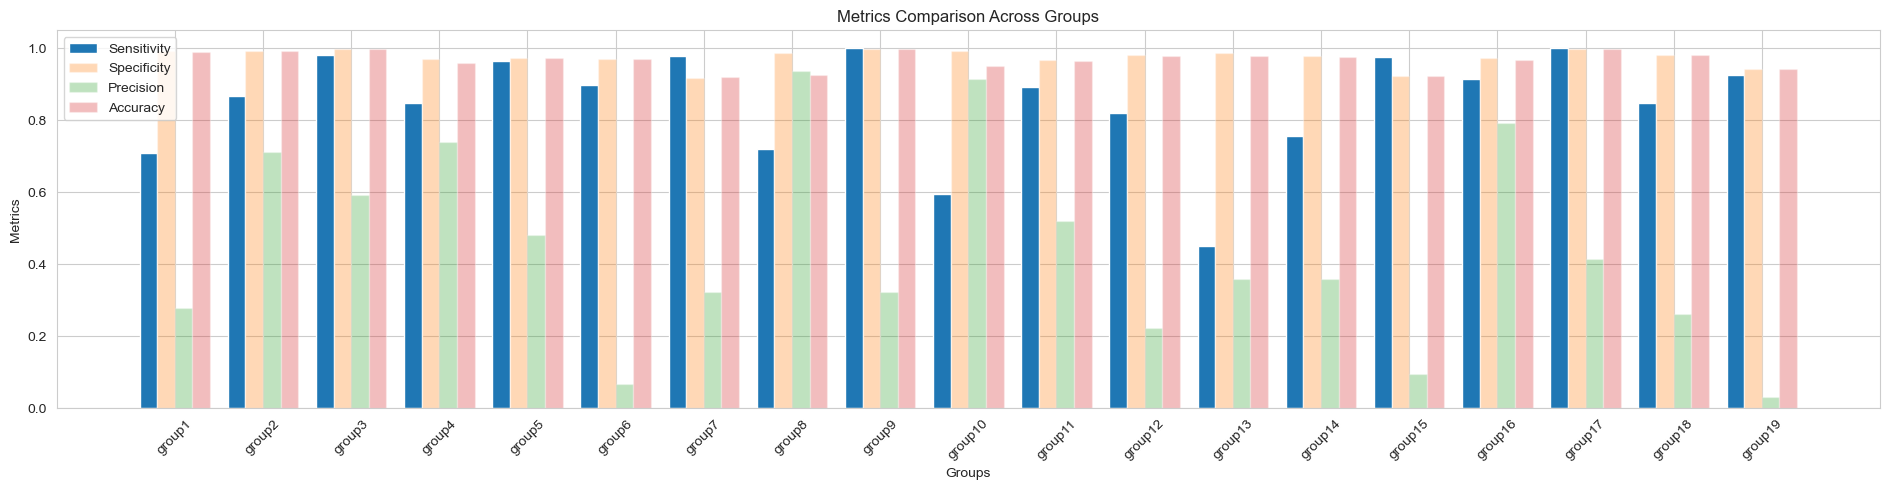

In [99]:
import numpy as np
import matplotlib.pyplot as plt

# Data for groups
groups = [
    'group1', 'group2', 'group3', 'group4', 'group5', 'group6', 'group7', 'group8', 
    'group9', 'group10', 'group11', 'group12', 'group13', 'group14', 'group15', 
    'group16', 'group17', 'group18', 'group19'
]

sensitivity = [0.7102625298329356, 0.868956994562531, 0.9824046920821115, 0.8483329806267916, 0.9651003336837775, 0.8993174061433447, 0.9780893567457091, 0.7204018587718454, 1.0, 0.595438166566372, 0.8938475952529669, 0.8212258796821793, 0.44961112711411055, 0.7565085516892746, 0.9764705882352941, 0.9153579254930606, 1.0, 0.8480932586300379, 0.927007299270073]

specificity = [0.992080502630638, 0.9938296628135841, 0.9973652061687877, 0.9711552584852513, 0.9740572287752077, 0.9718991581217168, 0.9178694082326334, 0.9861485599571491, 0.9987446392703979, 0.9934498244788296, 0.9690494842362521, 0.9807551981319753, 0.9864782773283944, 0.9792605636984983, 0.921901157065485, 0.9744787506830889, 0.998608376892268, 0.9819466290944822, 0.9417014531312915]
precision = [0.27740492170022374, 0.7107508187441879, 0.5936207914943886, 0.7397394710574656, 0.480688014388653, 0.06690364351910626, 0.32331788396995365, 0.9373950948217551, 0.32234432234432236, 0.914462915743411, 0.5202588479086762, 0.22406317745432022, 0.35780717841236576, 0.358543305514515, 0.09473871945782059, 0.7930977824298338, 0.41595441595441596, 0.26210690945651566, 0.03223622979947542]
accuracy = [0.9908793131510417, 0.9916881985134549, 0.9973068237304688, 0.9603313869900174, 0.9738397771661932, 0.9717369079589844, 0.9201922946506076, 0.9267437274639423, 0.9987453884548612, 0.9515670776367188, 0.9663278085214121, 0.9796829223632812, 0.977630615234375, 0.9758987426757812, 0.9223541259765625, 0.9687703450520834, 0.9986097547743056, 0.9809421115451389, 0.9416707356770834]

# Convert groups to numbers for the x-axis
x = np.arange(len(groups))

# Width for each bar
width = 0.2

# Plotting
fig, ax = plt.subplots(figsize=(19, 5))

# Create bars for each metric
ax.bar(x - 1.5*width, sensitivity, width, label='Sensitivity')
ax.bar(x - 0.5*width, specificity, width, label='Specificity', alpha=0.3)
ax.bar(x + 0.5*width, precision, width, label='Precision', alpha=0.3)
ax.bar(x + 1.5*width, accuracy, width, label='Accuracy', alpha=0.3)

# Labels and title
ax.set_xlabel('Groups')
ax.set_ylabel('Metrics')
ax.set_title('Metrics Comparison Across Groups')
ax.set_xticks(x)
ax.set_xticklabels(groups, rotation=45)
ax.legend()

plt.tight_layout()
plt.show()


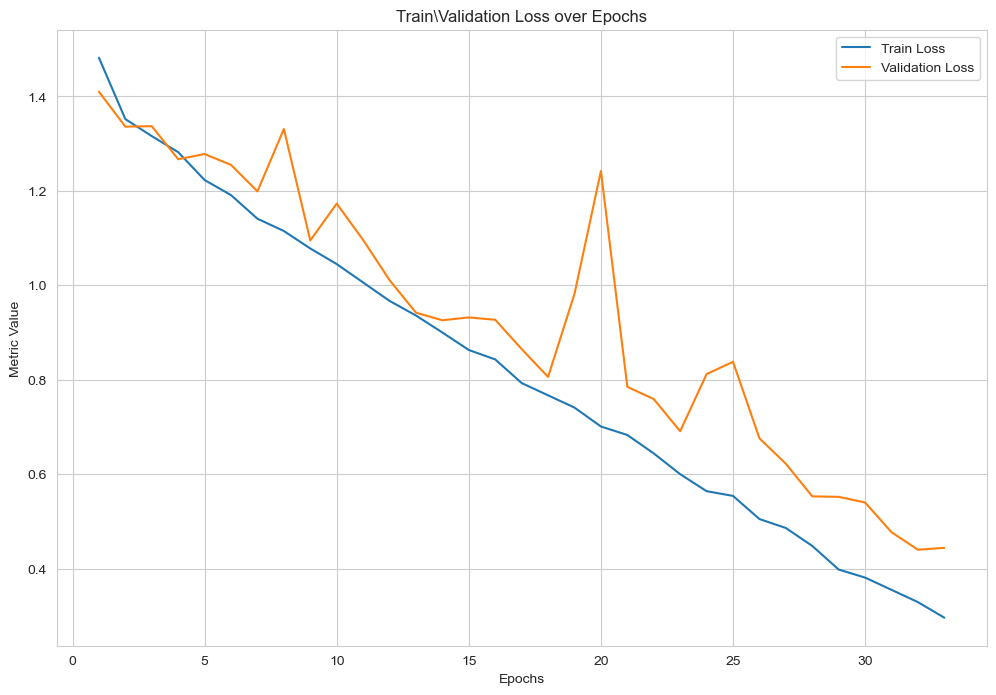

In [87]:
import matplotlib.pyplot as plt

# Data extracted from the logs (example values - replace these with your actual extracted data)
epochs = list(range(1, 34))  # replace with actual epoch numbers
train_loss = [1.482,
  1.352,
  1.316,
  1.282,
  1.223,
  1.191,
  1.141,
  1.115,
  1.078,
  1.045,
  1.006,
  0.967,
  0.936,
  0.9,
  0.863,
  0.843,
  0.793,
  0.767,
  0.741,
  0.701,
  0.683,
  0.644,
  0.6,
  0.564,
  0.554,
  0.505,
  0.486,
  0.448,
  0.398,
  0.381,
  0.355,
  0.329,
  0.296]
val_loss = [1.41,
  1.336,
  1.337,
  1.267,
  1.278,
  1.255,
  1.199,
  1.331,
  1.095,
  1.173,
  1.096,
  1.011,
  0.942,
  0.926,
  0.932,
  0.927,
  0.865,
  0.806,
  0.982,
  1.242,
  0.785,
  0.759,
  0.691,
  0.812,
  0.838,
  0.676,
  0.622,
  0.553,
  0.552,
  0.54,
  0.477,
  0.44,
  0.444]

"""
2024-10-02T21:14:11.317 | PROJECTNAME | INFO | 	Train Loss: 0.967
2024-10-02T21:14:11.317 | PROJECTNAME | INFO | 	 Val. Loss: 1.011
2024-10-03T08:19:30.261 | PROJECTNAME | INFO | 	Train Loss: 0.936
2024-10-03T08:19:30.261 | PROJECTNAME | INFO | 	 Val. Loss: 0.942
"""

# Plotting
metrics = {
    "Train Loss": train_loss,
    "Validation Loss": val_loss,
}

plt.figure(figsize=(12, 8))
for metric, values in metrics.items():
    plt.plot(epochs, values, label=metric)

plt.xlabel("Epochs")
plt.ylabel("Metric Value")
plt.title("Train\Validation Loss over Epochs")
plt.legend()
plt.grid(True)
# SAVE AS PDF 
plt.savefig('/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/loss_plot.pdf')
plt.show()



In [101]:
import os
import rasterio
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape

def binary_rasters_to_shapefiles(folder_path, output_folder):
    """
    Converts each binary raster in a folder to a shapefile containing only the '1' values (areas of interest).
    
    Parameters:
        folder_path (str): Path to the folder containing binary raster files.
        output_folder (str): Path to the folder where shapefiles will be saved.
    """
    # Ensure output folder exists
    os.makedirs(output_folder, exist_ok=True)
    
    # Process each file in the folder
    for file_name in os.listdir(folder_path):
        if file_name.endswith('.tif'):
            raster_path = os.path.join(folder_path, file_name)
            
            # Read the raster
            with rasterio.open(raster_path) as src:
                binary_array = src.read(1)  # Read the first band
                
                # Generate shapes for '1' values only
                mask = binary_array == 1
                shapes_gen = shapes(binary_array, mask=mask, transform=src.transform)
                
                # Create geometries from shapes generator
                geometries = []
                for geom, value in shapes_gen:
                    if value == 1:
                        geometries.append(shape(geom))
                
                # Save geometries to a shapefile
                gdf = gpd.GeoDataFrame(geometry=geometries, crs=src.crs)
                shapefile_name = os.path.splitext(file_name)[0] + '.shp'
                shapefile_path = os.path.join(output_folder, shapefile_name)
                
                # Write the shapefile
                gdf.to_file(shapefile_path)
                
                print(f"Shapefile created: {shapefile_path}")

# Example usage:
binary_rasters_to_shapefiles("/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh", "/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles")


Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles/group9_combined.shp
Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles/group8_combined.shp
Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles/group17_combined.shp
Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles/group10_combined.shp
Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles/group2_combined.shp
Shapefile created: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/D

In [102]:
import os
import geopandas as gpd
import pandas as pd

def combine_shapefiles(input_folder, output_shapefile):
    """
    Combines all shapefiles in a folder into one shapefile.
    
    Parameters:
        input_folder (str): Path to the folder containing shapefiles to combine.
        output_shapefile (str): Path for the combined output shapefile (including filename).
    """
    # List to store each shapefile's GeoDataFrame
    gdf_list = []
    
    # Loop through files in the input folder
    for file_name in os.listdir(input_folder):
        if file_name.endswith('.shp'):
            file_path = os.path.join(input_folder, file_name)
            
            # Read each shapefile and append to the list
            gdf = gpd.read_file(file_path)
            gdf_list.append(gdf)
    
    # Concatenate all GeoDataFrames
    combined_gdf = gpd.GeoDataFrame(pd.concat(gdf_list, ignore_index=True))
    
    # Set the CRS to the first shapefile's CRS (assuming all have the same CRS)
    combined_gdf.crs = gdf_list[0].crs
    
    # Save the combined GeoDataFrame as a new shapefile
    combined_gdf.to_file(output_shapefile)
    print(f"Combined shapefile created at: {output_shapefile}")

# Example usage:
combine_shapefiles("/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles", "/Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles.shp")


Combined shapefile created at: /Users/nirgut/Documents/Master_Files/pipeline_testing/model_train_data/128_overlap/DSM_tiles/test_groups/combined_pred_0.5thresh_shapefiles.shp


In [1]:
import torch
if torch.backends.mps.is_available():
    mps_device = torch.device("mps")
    x = torch.ones(1, device=mps_device)
    print (x)
else:
    print ("MPS device not found.")

MPS device not found.


In [3]:
if torch.backends.mps.is_available():
    print("MPS backend available on Apple Silicon.")
else:
    print("No MPS or CUDA backend available.")



No MPS or CUDA backend available.


    Epoch  Train Loss  Val Loss  Precision  Recall     F1  Accuracy  \
0       1       0.172     0.130      0.769   0.263  0.392     0.974   
1       2       0.127     0.121      0.537   0.264  0.354     0.969   
2       3       0.119     0.112      0.700   0.378  0.491     0.975   
3       4       0.110     0.101      0.676   0.600  0.636     0.978   
4       5       0.102     0.098      0.674   0.662  0.668     0.979   
..    ...         ...       ...        ...     ...    ...       ...   
89     90       0.034     0.045      0.922   0.885  0.903     0.994   
90     91       0.034     0.045      0.926   0.882  0.904     0.994   
91     92       0.033     0.044      0.926   0.883  0.904     0.994   
92     93       0.033     0.043      0.935   0.875  0.904     0.994   
93     94       0.033     0.043      0.929   0.881  0.904     0.994   

    Sensitivity  Specificity  
0         0.263        0.997  
1         0.264        0.993  
2         0.378        0.995  
3         0.600        

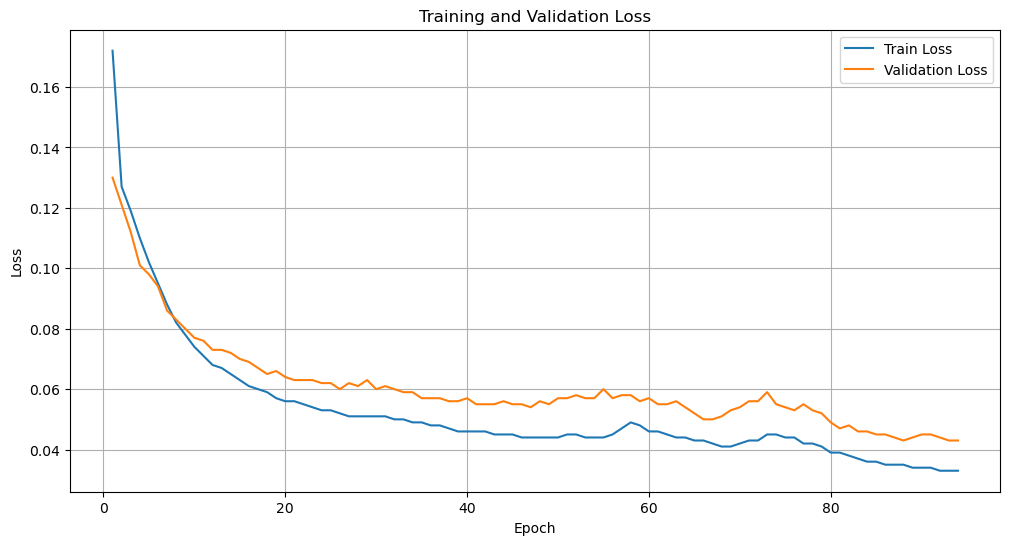

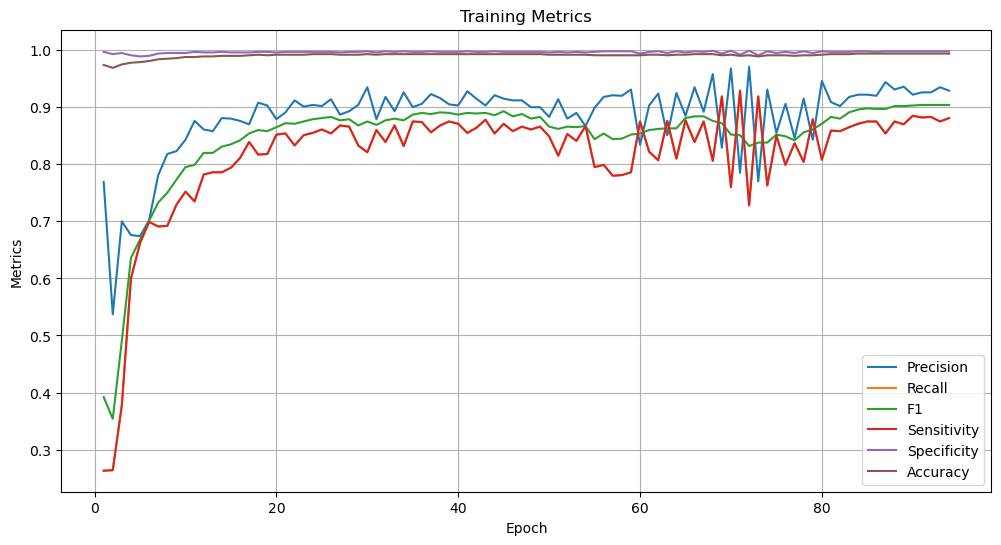

In [3]:
import re
import pandas as pd

def parse_training_log(log_file_path, output_csv_path=None):
    """
    Parse training log file and extract epoch metrics into a pandas DataFrame or CSV.
    
    Parameters:
    log_file_path (str): Path to the input log file
    output_csv_path (str, optional): Path to save the CSV file. If None, returns DataFrame
    
    Returns:
    pandas.DataFrame: DataFrame containing all metrics if output_csv_path is None
    """
    # Initialize lists to store the metrics
    metrics = {
        'Epoch': [],
        'Train Loss': [],
        'Val Loss': [],
        'Precision': [],
        'Recall': [],
        'F1': [],
        'Accuracy': [],
        'Sensitivity': [],
        'Specificity': []
    }
    
    current_epoch = 0
    
    with open(log_file_path, 'r') as file:
        lines = file.readlines()
        
        for line in lines:
            # Extract epoch number
            epoch_match = re.search(r'Epoch: (\d+)', line)
            if epoch_match:
                current_epoch = int(epoch_match.group(1))
                metrics['Epoch'].append(current_epoch)
                continue
            
            # Extract Train Loss
            if 'Train Loss:' in line:
                train_loss = float(line.split('Train Loss:')[1].strip())
                metrics['Train Loss'].append(train_loss)
                
            # Extract Val Loss
            elif 'Val. Loss:' in line:
                val_loss = float(line.split('Val. Loss:')[1].strip())
                metrics['Val Loss'].append(val_loss)
                
            # Extract Precision
            elif 'Precision:' in line:
                precision = float(line.split('Precision:')[1].strip())
                metrics['Precision'].append(precision)
                
            # Extract Recall
            elif 'Recall:' in line:
                recall = float(line.split('Recall:')[1].strip())
                metrics['Recall'].append(recall)
                
            # Extract F1
            elif 'F1:' in line:
                f1 = float(line.split('F1:')[1].strip())
                metrics['F1'].append(f1)
                
            # Extract Accuracy
            elif 'Accuracy:' in line:
                accuracy = float(line.split('Accuracy:')[1].strip())
                metrics['Accuracy'].append(accuracy)
                
            # Extract Sensitivity
            elif 'Sensitivity:' in line:
                sensitivity = float(line.split('Sensitivity:')[1].strip())
                metrics['Sensitivity'].append(sensitivity)
                
            # Extract Specificity
            elif 'Specificity:' in line:
                specificity = float(line.split('Specificity:')[1].strip())
                metrics['Specificity'].append(specificity)
    
    # Create DataFrame
    df = pd.DataFrame(metrics)
    
    # Save to CSV if path is provided
    if output_csv_path:
        df.to_csv(output_csv_path, index=False)
        return None
    
    return df

# Example usage:
if __name__ == "__main__":
    # To save directly to CSV:
    parse_training_log("/Users/nirgut/Documents/output11_12_extra_samp_model.log", "/Users/nirgut/Documents/output11_12_extra_samp_model.csv")
    
    # To get DataFrame:
    df = parse_training_log("/Users/nirgut/Documents/output11_12_extra_samp_model.log")
    print(df)
    # plot the data
    import matplotlib.pyplot as plt
    
    plt.figure(figsize=(12, 6))
    plt.plot(df['Epoch'], df['Train Loss'], label='Train Loss')
    plt.plot(df['Epoch'], df['Val Loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # plot the rest of the data
    plt.figure(figsize=(12, 6))
    plt.plot(df['Epoch'], df['Precision'], label='Precision')
    plt.plot(df['Epoch'], df['Recall'], label='Recall')
    plt.plot(df['Epoch'], df['F1'], label='F1')
    plt.plot(df['Epoch'], df['Sensitivity'], label='Sensitivity')
    plt.plot(df['Epoch'], df['Specificity'], label='Specificity')
    plt.plot(df['Epoch'], df['Accuracy'], label='Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Metrics')
    plt.title('Training Metrics')
    plt.legend()
    plt.grid(True)

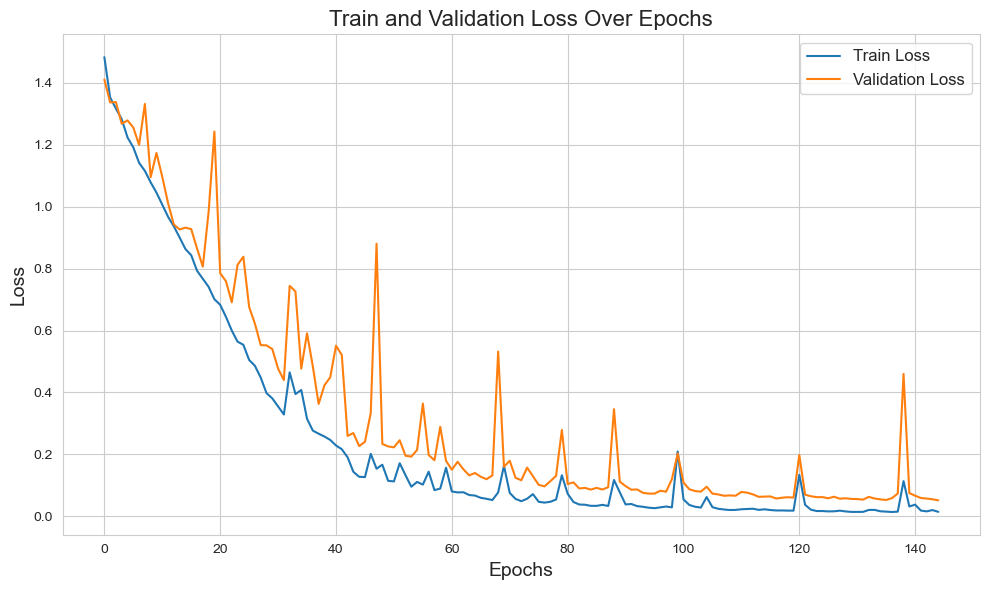

In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

# Define the path to the input text file (example content provided)
file_path = '/Users/nirgut/Documents/Master_Files/UNet_files/Trained_Models/Model_Checkpoints_128_overlap_64batch/logs/complete_training_log.csv'

# Load the file into a DataFrame
data = pd.read_csv(file_path)
# save as csv
# data.to_csv('/Users/nirgut/Documents/Master_Files/UNet_files/Trained_Models/Model_Checkpoints_128_overlap_64batch/metrics.csv', index=False)

# print(data)

# Plot Train Loss and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(data['Train Loss'], label='Train Loss')
plt.plot(data['Val Loss'], label='Validation Loss')
# plt.plot(data['Sensitivity'], label='Sensitivity')
# plt.plot(data['Specificity'], label='Specificity')

# Customize the plot
plt.title('Train and Validation Loss Over Epochs', fontsize=16)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True)

# save as pdf
plt.savefig('/Users/nirgut/Documents/Master_Files/UNet_files/Trained_Models/Model_Checkpoints_128_overlap_64batch/loss_plot.pdf')

# Show the plot
plt.tight_layout()
plt.show()

In [44]:
import pandas as pd

# Specify input and output file paths
input_file = "/Users/nirgut/Documents/aws_course/Model_Training/Model_Checkpoints_64batch/metrics.txt"
output_file = "/Users/nirgut/Documents/aws_course/Model_Training/Model_Checkpoints_64batch/metrics.csv"

# Read the text file and save as CSV
df = pd.read_csv(input_file)
df.to_csv(output_file, index=False)

print(f"CSV file saved as: {output_file}")


CSV file saved as: /Users/nirgut/Documents/aws_course/Model_Training/Model_Checkpoints_64batch/metrics.csv


In [49]:
import os
import geopandas as gpd
import random

def random_sample_shapefile(input_shapefile, output_shapefile, num_samples):
    """
    Randomly selects a specified number of polygons from an input shapefile
    and saves them to a new shapefile.

    Parameters:
    -----------
    input_shapefile : str
        Path to the input shapefile containing polygons.
    output_shapefile : str
        Path to save the output shapefile with the random selection.
    num_samples : int
        Number of polygons to randomly select.

    Returns:
    --------
    None
    """
    # Load the shapefile
    gdf = gpd.read_file(input_shapefile)
    
    # Check if the requested number of samples is less than or equal to the number of polygons
    if num_samples > len(gdf):
        raise ValueError("Number of samples exceeds the number of available polygons in the shapefile.")
    
    # Randomly sample the polygons
    sampled_gdf = gdf.sample(n=num_samples, random_state=42)  # Fix random_state for reproducibility

    # Ensure the output directory exists
    output_dir = os.path.dirname(output_shapefile)
    os.makedirs(output_dir, exist_ok=True)
    
    # Save the sampled polygons to a new shapefile
    sampled_gdf.to_file(output_shapefile, driver='ESRI Shapefile')
    
    print(f"Random sample of {num_samples} polygons saved to: {output_shapefile}")



In [52]:
# Define paths
input_shapefile = "/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/base_shp/extra_train_tiles_200overlap.shp"
output_shapefile = "/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/base_shp/extra_train_tiles_200overlap_random3000.shp"
num_samples = 3000  # Number of polygons to select

# Call the function
random_sample_shapefile(input_shapefile, output_shapefile, num_samples)


Random sample of 3000 polygons saved to: /Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/base_shp/extra_train_tiles_200overlap_random3000.shp


In [56]:
import os
import geopandas as gpd

def delete_files_by_polygon_name(shapefile_path, target_dir, name_column='filename'):
    """
    Deletes files from a target directory based on polygon names in a shapefile.

    Parameters:
    - shapefile_path: Path to the shapefile with polygons.
    - target_dir: Directory containing the files to delete.
    - name_column: The column in the shapefile containing file names to match.
    """

    # Load the shapefile
    gdf = gpd.read_file(shapefile_path)

    # Iterate over each polygon in the shapefile
    for idx, row in gdf.iterrows():
        polygon_name = row[name_column]

        # Construct the full path to the file in the target directory
        file_name = f'{polygon_name}'
        target_file = os.path.join(target_dir, file_name)

        # Check if the file exists in the target directory
        if os.path.exists(target_file):
            # Delete the file
            os.remove(target_file)
            print(f'Deleted {file_name} from {target_dir}')
        else:
            print(f'File {file_name} not found in {target_dir}')

    print(f"Deletion process completed for {len(gdf)} files.")


In [58]:
# Define paths
shapefile_path = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/tiles_to_remove/tiles_to_remove.shp'
target_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000'

# Call the function
delete_files_by_polygon_name(shapefile_path, target_dir, name_column='filename')


Deleted tile_70_302.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_71_313.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_71_307.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_74_322.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_75_327.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_78_311.tif from /Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000
Deleted tile_75_326.tif from /Users/nirgut/Documents/Maste

In [68]:
src = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000/tile_304_390.tif'
ref = '/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_new_boundaries.tif'
out = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/Mask_tiles/tile_304_390.tif'
st.clip_raster_by_raster(src, ref, out)


In [66]:
# Define paths
src_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000'  # Directory with raster tiles to crop
ref_raster = '/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_new_boundaries.tif'  # Reference raster for cropping
output_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/Mask_tiles'  # Output directory to save cropped tiles

# Call the function
crop_tiles_with_reference(src_dir, ref_raster, output_dir)


  0%|          | 6/15855 [01:34<69:25:25, 15.77s/it]


KeyboardInterrupt: 

In [70]:
import os
import rasterio
from rasterio.mask import mask
from rasterio.windows import from_bounds
from rasterio.io import MemoryFile

def clip_raster_by_tiles(tiles_dir, mask_raster_path, output_dir):
    """
    Clips a large mask raster using the boundaries of tiles in a directory and saves the results.

    Parameters:
    - tiles_dir (str): Path to the directory containing tile rasters.
    - mask_raster_path (str): Path to the large mask raster.
    - output_dir (str): Path to save the clipped rasters.

    Returns:
    - None
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Open the large mask raster
    with rasterio.open(mask_raster_path) as mask_raster:
        for tile_name in tqdm.tqdm(os.listdir(tiles_dir)):
            tile_path = os.path.join(tiles_dir, tile_name)
            if not tile_path.endswith('.tif'):
                continue
            
            # Open the tile to get its bounds
            with rasterio.open(tile_path) as tile_raster:
                bounds = tile_raster.bounds

                # Define a window to clip the mask raster
                window = from_bounds(
                    bounds.left, bounds.bottom, bounds.right, bounds.top,
                    transform=mask_raster.transform
                )
                
                # Read the clipped data
                data = mask_raster.read(window=window)
                transform = mask_raster.window_transform(window)
                
                # Save the clipped raster to the output folder
                output_path = os.path.join(output_dir, tile_name)
                profile = mask_raster.profile
                profile.update({
                    "height": data.shape[1],
                    "width": data.shape[2],
                    "transform": transform
                })
                
                with rasterio.open(output_path, "w", **profile) as dst:
                    dst.write(data)
            # print(f"Saved clipped raster: {output_path}")

# Example usage:
src_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/DSM_tiles/train_combined_w_rand3000'  # Directory with raster tiles to crop
ref_raster = '/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_new_boundaries.tif'  # Reference raster for cropping
output_dir = '/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap+200overlap_train/Mask_tiles'  # Output directory to save cropped tiles
clip_raster_by_tiles(src_dir, ref_raster, output_dir)


100%|██████████| 15856/15856 [04:59<00:00, 52.91it/s]


In [1]:
import os
import re

# Define the directory where your files are located
directory = "/Users/nirgut/Documents/Model_Checkpoints_128batch"

# Regular expression to match the file pattern 'unet_epoch_X' where X is a number
pattern = r"unet_epoch_(\d+)"

# Loop through the files in the directory
for filename in os.listdir(directory):
    match = re.match(pattern, filename)
    if match:
        # Extract the number, add 300 to it
        original_number = int(match.group(1))
        new_number = original_number + 300
        new_filename = f"{new_number}"
        
        # Full paths for renaming
        old_path = os.path.join(directory, filename)
        new_path = os.path.join(directory, new_filename)
        
        # Rename the file
        os.rename(old_path, new_path)
        print(f"Renamed: {filename} -> {new_filename}")


Renamed: unet_epoch_79.pth -> 379
Renamed: unet_epoch_45.pth -> 345
Renamed: unet_epoch_278.pth -> 578
Renamed: unet_epoch_244.pth -> 544
Renamed: unet_epoch_92.pth -> 392
Renamed: unet_epoch_86.pth -> 386
Renamed: unet_epoch_132.pth -> 432
Renamed: unet_epoch_127.pth -> 427
Renamed: unet_epoch_133.pth -> 433
Renamed: unet_epoch_87.pth -> 387
Renamed: unet_epoch_251.pth -> 551
Renamed: unet_epoch_93.pth -> 393
Renamed: unet_epoch_245.pth -> 545
Renamed: unet_epoch_279.pth -> 579
Renamed: unet_epoch_292.pth -> 592
Renamed: unet_epoch_44.pth -> 344
Renamed: unet_epoch_50.pth -> 350
Renamed: unet_epoch_78.pth -> 378
Renamed: unet_epoch_46.pth -> 346
Renamed: unet_epoch_52.pth -> 352
Renamed: unet_epoch_284.pth -> 584
Renamed: unet_epoch_85.pth -> 385
Renamed: unet_epoch_119.pth -> 419
Renamed: unet_epoch_131.pth -> 431
Renamed: unet_epoch_130.pth -> 430
Renamed: unet_epoch_124.pth -> 424
Renamed: unet_epoch_246.pth -> 546
Renamed: unet_epoch_84.pth -> 384
Renamed: unet_epoch_252.pth -> 55

In [2]:
import os

# Define the directory where your files are located
directory = "/Users/nirgut/Documents/Model_Checkpoints_128batch"

# Loop through the files in the directory
for filename in os.listdir(directory):
    # Check if the filename is a number
    if filename.isdigit():
        new_filename = f"unet_epoch_{filename}.pth"

        # Full paths for renaming
        old_path = os.path.join(directory, filename)
        new_path = os.path.join(directory, new_filename)

        # Rename the file
        os.rename(old_path, new_path)
        print(f"Renamed: {filename} -> {new_filename}")


Renamed: 307 -> unet_epoch_307.pth
Renamed: 551 -> unet_epoch_551.pth
Renamed: 338 -> unet_epoch_338.pth
Renamed: 300 -> unet_epoch_300.pth
Renamed: 336 -> unet_epoch_336.pth
Renamed: 309 -> unet_epoch_309.pth
Renamed: 558 -> unet_epoch_558.pth
Renamed: 533 -> unet_epoch_533.pth
Renamed: 365 -> unet_epoch_365.pth
Renamed: 362 -> unet_epoch_362.pth
Renamed: 396 -> unet_epoch_396.pth
Renamed: 502 -> unet_epoch_502.pth
Renamed: 354 -> unet_epoch_354.pth
Renamed: 353 -> unet_epoch_353.pth
Renamed: 505 -> unet_epoch_505.pth
Renamed: 566 -> unet_epoch_566.pth
Renamed: 330 -> unet_epoch_330.pth
Renamed: 592 -> unet_epoch_592.pth
Renamed: 559 -> unet_epoch_559.pth
Renamed: 337 -> unet_epoch_337.pth
Renamed: 308 -> unet_epoch_308.pth
Renamed: 301 -> unet_epoch_301.pth
Renamed: 306 -> unet_epoch_306.pth
Renamed: 352 -> unet_epoch_352.pth
Renamed: 503 -> unet_epoch_503.pth
Renamed: 355 -> unet_epoch_355.pth
Renamed: 397 -> unet_epoch_397.pth
Renamed: 363 -> unet_epoch_363.pth
Renamed: 364 -> unet

In [5]:
import torch
from torchviz import make_dot
from model import build_unet

# Instantiate the model
model = build_unet()

# Create a dummy input tensor
dummy_input = torch.randn(1, 1, 256, 256)  # Batch size: 1, Channels: 1, Height: 256, Width: 256

# Perform a forward pass to get outputs
outputs = model(dummy_input)

# Generate the model graph
model_graph = make_dot(outputs, params=dict(model.named_parameters()))

# Save the plot to a file
model_graph.render("unet_architecture", format="png")

# Display the graph
model_graph.view()


'unet_architecture.pdf'

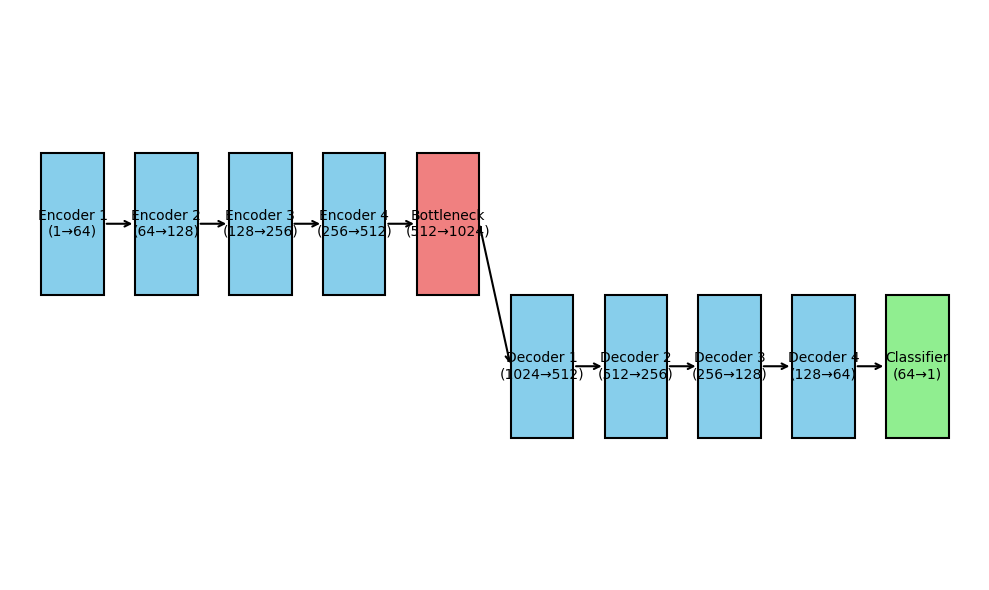

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow

def add_block(ax, x, y, width, height, label, color="skyblue"):
    """Add a block (rectangle) to the plot."""
    rect = Rectangle((x, y), width, height, edgecolor="black", facecolor=color, lw=1.5)
    ax.add_patch(rect)
    ax.text(x + width / 2, y + height / 2, label, ha="center", va="center", fontsize=10)

def add_arrow(ax, start, end):
    """Add an arrow between blocks."""
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.5))

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Encoder blocks
add_block(ax, 0, 4, 2, 1, "Encoder 1\n(1→64)")
add_block(ax, 3, 4, 2, 1, "Encoder 2\n(64→128)")
add_block(ax, 6, 4, 2, 1, "Encoder 3\n(128→256)")
add_block(ax, 9, 4, 2, 1, "Encoder 4\n(256→512)")

# Bottleneck
add_block(ax, 12, 4, 2, 1, "Bottleneck\n(512→1024)", color="lightcoral")

# Decoder blocks
add_block(ax, 15, 3, 2, 1, "Decoder 1\n(1024→512)")
add_block(ax, 18, 3, 2, 1, "Decoder 2\n(512→256)")
add_block(ax, 21, 3, 2, 1, "Decoder 3\n(256→128)")
add_block(ax, 24, 3, 2, 1, "Decoder 4\n(128→64)")

# Classifier
add_block(ax, 27, 3, 2, 1, "Classifier\n(64→1)", color="lightgreen")

# Arrows between blocks
add_arrow(ax, (2, 4.5), (3, 4.5))  # Between Encoder 1 and 2
add_arrow(ax, (5, 4.5), (6, 4.5))  # Between Encoder 2 and 3
add_arrow(ax, (8, 4.5), (9, 4.5))  # Between Encoder 3 and 4
add_arrow(ax, (11, 4.5), (12, 4.5))  # To Bottleneck
add_arrow(ax, (14, 4.5), (15, 3.5))  # From Bottleneck to Decoder 1
add_arrow(ax, (17, 3.5), (18, 3.5))  # Between Decoder 1 and 2
add_arrow(ax, (20, 3.5), (21, 3.5))  # Between Decoder 2 and 3
add_arrow(ax, (23, 3.5), (24, 3.5))  # Between Decoder 3 and 4
add_arrow(ax, (26, 3.5), (27, 3.5))  # To Classifier

# Adjust the axes
ax.set_xlim(-1, 30)
ax.set_ylim(2, 6)
ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:
import rasterio
import numpy as np

def calculate_valid_area_2039(raster_path):
    pixel_size = 0.5  # Pixel size in meters
    pixel_area = pixel_size ** 2  # Area of one pixel (0.5 x 0.5 = 0.25 m²)
    
    # Open the raster
    with rasterio.open(raster_path) as src:
        data = src.read(1)  # Read the first band
        nodata = src.nodata  # Get the nodata value
        print(nodata)

        # Mask nodata pixels
        valid_pixels = np.sum(data != nodata)
        print(valid_pixels)

        # Calculate valid area
        valid_area = valid_pixels * pixel_area

    return valid_area

# Example usage
raster_path = "/Users/nirgut/Documents/Master_Files/Raster_Files/Full_DSM/Full_Hillshade.tif"
area = calculate_valid_area_2039(raster_path)
print(f"Valid area without nodata pixels: {area:.2f} square meters")



0.0
2087167059
Valid area without nodata pixels: 521791764.75 square meters


In [7]:
import geopandas as gpd

# Load the shapefile
input_file = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/extra_tiles_model/128_batch/epoch881/threshold0.8/combined_shapefile.shp"
output_file = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/extra_tiles_model/128_batch/epoch881/threshold0.8/combined_shapefile_5m_filter.shp"

# Read the shapefile into a GeoDataFrame
gdf = gpd.read_file(input_file)

# Filter polygons with "Area" >= 20
filtered_gdf = gdf[gdf["Area"] >= 5]

# Save the filtered polygons to a new shapefile
filtered_gdf.to_file(output_file)

print(f"Filtered shapefile saved as {output_file}")


Filtered shapefile saved as /Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/extra_tiles_model/128_batch/epoch881/threshold0.8/combined_shapefile_5m_filter.shp


In [4]:
import os
import rasterio
import numpy as np

def find_global_min_max(directory):
    """
    Traverse a directory with raster files and find the global minimum and maximum values.
    
    Args:
        directory (str): Path to the directory containing raster files.
    
    Returns:
        tuple: (global_min, global_max)
    """
    global_min = float('inf')
    global_max = float('-inf')

    for root, _, files in os.walk(directory):
        for file in tqdm.tqdm(files):
            if file.endswith(('.tif', '.tiff')):  # Modify as needed for your raster format
                raster_path = os.path.join(root, file)
                try:
                    with rasterio.open(raster_path) as src:
                        data = src.read(1, masked=True)  # Read the first band, mask invalid data
                        local_min = np.min(data)
                        local_max = np.max(data)

                        global_min = min(global_min, local_min)
                        global_max = max(global_max, local_max)

                        # print(f"Processed: {file} | Min: {local_min} | Max: {local_max}")
                except Exception as e:
                    print(f"Error processing {file}: {e}")

    return global_min, global_max

# Specify the directory containing the raster files
raster_directory = "/Users/nirgut/Documents/Master_Files/UNet_files/Train_Test_Data/128overlap_alldata/Mask_tiles"

# Run the function and print results
min_value, max_value = find_global_min_max(raster_directory)
print(f"Global Min: {min_value}, Global Max: {max_value}")


100%|██████████| 32055/32055 [03:49<00:00, 139.94it/s]

Global Min: 0.0, Global Max: 1.0
